# EDA - Exploratory Data Analysis

Survey of veterinary students who study (or studied) in Hungary, about neurodivergence, mental health and wellbeing.

**How to read this notebook**
- Every chart has the same notes: **Columns used**, **What the graph shows**, **Method** and **Reading the numbers** (only when a statistical test is used), **Conclusions** and, where needed, **Limits**. Column numbers refer to `datasets/codebook.csv`.
- The **Statistical methods** section below explains every test and number used in the notebook, and the **Summary of statistical results** at the end lists every result in one place.
- All tests are two-sided, and p < 0.05 is called *significant*. Many tests are run in this notebook and none is corrected for multiple testing: about 1 test in 20 can come out "significant" by chance. A single p-value close to 0.05 is a hint, not proof.
- The survey was answered once, by students who chose to take part. The results show **links, not causes**.

## Statistical methods

This section explains the statistical tools used in the notebook and how to read their numbers. Each chart then has a short **Reading the numbers** note that applies this to its own results.

### Two questions behind every result

Every statistical result answers two separate questions, and the notebook always gives a number for each:

1. **How big is the difference or link?** This is the **effect size**: for example a correlation ρ = 0.73, or two averages 4.2 vs 3.5.
2. **Could it be just chance?** This is the **p-value**: for example p < 0.001.

The two are not the same thing and one does not follow from the other. A strong link in a very small sample can have a large p-value, and a tiny link in a huge sample can have a very small one. That is why both are always reported.

### The p-value

Every test starts from a **null hypothesis**: the "nothing is going on" explanation, for example *"the two groups do not differ"* or *"the two questions are not linked"*.

The **p-value** is the probability of getting a result **at least as extreme as the one observed**, if the null hypothesis were true and only chance were at work.

- **p = 0.003** means: if there were really no difference, a gap this big would appear in only about 3 of every 1,000 samples of this size. That is unlikely, so we conclude the difference is probably real.
- **p = 0.30** means: a gap like this would appear in 30 of every 100 samples even with no real difference. That is common, so chance is a perfectly good explanation.
- By convention, **p < 0.05** (less than 1 chance in 20) is called **statistically significant**.

Three common mistakes to avoid:
- **p is not the probability that the result is wrong** or that the null hypothesis is true. It is the probability of the data *assuming* the null hypothesis is true.
- **A small p does not mean a big or important effect.** It only means chance is an unlikely explanation. The effect size tells you how big it is.
- **"Not significant" does not mean "no difference".** It means this sample could not show one. With small groups, real but modest differences often come out "not significant" (see *Sample size and power* below).

All tests in this notebook are **two-sided**: they look for a difference in either direction (higher *or* lower).

### Why rank-based (non-parametric) tests

Most answers in the survey are on a 1–5 or 1–7 scale (*strongly disagree … strongly agree*). These are **ordered categories**, not exact measurements: the step from 1 to 2 is not necessarily the same size as the step from 4 to 5. Many of the answers are also skewed (for example, most students answered 4 or 5 on overwhelm), and several groups are small.

Classic tests such as the t-test or Pearson correlation assume measured, roughly bell-shaped data. The tests used here instead work on **ranks**: every answer is replaced by its position in the sorted list (1st, 2nd, 3rd…). Only the *order* of the answers matters, so they are valid for this kind of data. Tied answers, which are very common on a 1–5 scale, share the average of their ranks.

### Spearman correlation (ρ, "rho")

**Question:** when one answer goes up, does the other tend to go up (or down) too?

**How it works**
1. Rank all students on the first variable, and separately on the second.
2. ρ is the ordinary correlation between the two sets of ranks.

**Reading ρ**

| ρ | Meaning |
|---|---|
| +1 | The two rankings are identical: the higher on one, always the higher on the other |
| about +0.5 | Strong positive link |
| about +0.3 | Moderate positive link |
| about +0.1 | Weak positive link |
| 0 | No link |
| negative | The higher on one, the *lower* on the other (same strength scale) |

A rough guide to what ρ means in practice: **ρ² is about the share of the variation in one ranking that goes together with the other**. ρ = 0.73 gives ρ² ≈ 0.53 (about half), while ρ = 0.26 gives ρ² ≈ 0.07 (about 7%).

**The p-value of ρ.** The null hypothesis is that the true correlation in the population is 0. ρ is turned into a t-statistic with n − 2 degrees of freedom (n = number of students):

$$t = \rho\sqrt{\frac{n-2}{1-\rho^2}}$$

The larger t is, the less likely the correlation is due to chance. Because t grows with n, the same ρ is more convincing in a larger sample.

**Used for:** combining the two overwhelm questions, overwhelm vs distress, lifestyle vs year of study, professors vs teaching style, fear of disclosure vs environment, and checking the challenges ranking.

### Mann-Whitney U test

**Question:** do students in one group tend to give **higher answers** than students in another, independent group (for example ND vs not ND)?

**How it works**
1. Put the answers of both groups together and rank them from lowest to highest.
2. **U** counts, for every possible pair of one student from each group, how often the student from group A answered higher than the student from group B (ties count as half).
3. If the groups do not differ, group A should "win" about half of the pairs. The p-value says how unusual the observed number of wins is.

The notebook shows the **averages** of each group because they are easy to read, but the test itself compares the **ranks** of the whole groups, not the averages.

**Used for:** high vs low overwhelm, year groups, ND vs not ND (environment, social support), diagnosed vs self-identified (fear of disclosure).

### Wilcoxon signed-rank test

**Question:** the **same students** answered two questions. Do they rate one higher than the other?

**How it works**
1. For each student, take the difference between their two answers (for example family − cultural environment).
2. Students with a difference of 0 are set aside. The others are ranked by the *size* of their difference.
3. The test compares the ranks of the positive differences with the ranks of the negative ones. If neither question is rated higher, they should balance out.

This is a **paired** test: it compares each student with themselves, which removes the differences *between* students and makes it more sensitive than comparing two separate groups.

**Used for:** family vs cultural environment, and comparing the three sources of social support two at a time.

### Friedman test

**Question:** the same students rated **three or more** things. Is at least one of them rated differently?

**How it works:** for each student, the three sources (partner, family, friends) are ranked 1st, 2nd and 3rd. If students had no general preference, each source would get about the same average rank. The test checks whether the average ranks differ more than chance would allow.

It only says that *some* difference exists, not *which* one. That is why it is followed by Wilcoxon tests on each pair.

**Used for:** partner vs family vs friends support.

### Fisher's exact test

**Question:** in a 2 × 2 table of counts (for example *ND / not ND* × *chose this answer / did not*), is the proportion different between the two rows?

**How it works:** keeping the row and column totals fixed, it calculates **exactly** how likely every possible table would be if there were no difference, and adds up the probability of all tables at least as extreme as the observed one.

The more common chi-square test uses an approximation that becomes unreliable when some cells have fewer than about 5 students, which is often the case here. Fisher's test needs no approximation.

**Used for:** how ND and not ND students define neurodivergence, and challenges by condition.

### McNemar exact test

**Question:** the same students answered two **yes / no** questions. Is "yes" more common for one question than for the other?

**How it works**
1. Students who gave the **same answer** to both questions (yes-yes or no-no) carry no information about a change, so they are set aside.
2. Only the students who **changed** their answer are used: *No → Yes* and *Yes → No*.
3. If neither question gets more "yes" answers, a change should be equally likely in each direction, like a coin flip. The exact test calculates how unlikely the observed split is, using the binomial distribution with probability 0.5.

**Used for:** strengths as a student (52) vs as a future vet (53).

### Multiple testing

At p < 0.05, **1 test in 20 is expected to come out "significant" by chance** even when nothing is going on. This notebook runs many tests (about 100 in total, 48 in the challenges-by-condition heatmap alone), so some significant results are expected to be false alarms.

A **correction** such as Bonferroni divides the threshold by the number of tests (for 48 tests: 0.05 / 48 ≈ 0.001), which removes false alarms but also hides many real effects. Because this is an exploratory analysis, no correction is applied. Instead:
- results with **very small p-values** (p < 0.001) or that **repeat across related questions** are treated as solid;
- **single results close to 0.05** are treated as hints that need confirming in another sample.

### Sample size and power

**Power** is the chance that a test detects a difference or link that really exists. It depends on how big the effect is and on how many students are in each group.

- With 79 students, a correlation needs to be about ρ = 0.22 to reach p < 0.05; with 40 students, about ρ = 0.31.
- To detect a link **reliably** (80% of the time), it needs to be about ρ = 0.31 with 79 students and ρ = 0.43 with 40.
- Comparisons involving small groups (11 low-overwhelm students, 10 graduates, 10–27 students per condition) can only detect **large** differences.

This is why many results in this notebook are described as *"not significant, but could be real"* rather than *"no difference"*.

### Which test is used where

| Data | Comparison | Test |
|---|---|---|
| Two rating questions, every student answered both | Is there a link? | Spearman correlation |
| A rating, two separate groups of students | Does one group answer higher? | Mann-Whitney U |
| Two ratings by the same students | Is one rated higher? | Wilcoxon signed-rank |
| Three or more ratings by the same students | Is any rated differently? | Friedman |
| Yes / no (or chose / did not), two separate groups | Is the proportion different? | Fisher's exact |
| Two yes / no questions by the same students | Is "yes" more common for one? | McNemar exact |

In [25]:
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## Extract data to analyze

**Columns used**
- `forms-answers-cleaned-hungary.csv`: the answers already cleaned and filtered to students who study or studied in Hungary (see `cleanup.ipynb`).

**What the checks below do**
- Make sure the assumptions the whole analysis relies on are true: no duplicate submissions, every respondent consented (column 1), every respondent studied in Hungary (column 7), and every scored answer is inside its scale (PHQ-9 and GAD-7: 0–3, MSPSS: 1–7, the other rating questions: 1–5). The notebook stops with an error if one of them fails.
- Count the missing answers in the two scored questionnaires.

**Conclusions**
- All checks pass: **79 students, no duplicates, no out-of-range answers.**
- The GAD-7 (anxiety) is complete. In the PHQ-9 (depression), 5 students skipped one item and 2 students skipped the whole questionnaire. How this is handled is explained with the screening chart.

In [26]:
df = pd.read_csv("./datasets/forms-answers-cleaned-hungary.csv")

In [27]:
display(df.head(5))

,0,1,3,4,5,6,7,8,9,10,...,92,93,94,95,96,97,98,99,100,101
0,2026-04-19 19:33:39+00:00,Yes,20-24,Woman,Lebanese,NaN,Hungary,5+,Diagnosed neurodivergent (you have received a ...,ASD – Autism Spectrum Disorder;OCD – Obsessive...,...,7,7,7,7,7,7,5,5,Teach differently and interact more rather tha...,NaN
1,2026-04-19 20:01:35+00:00,Yes,30-34,Woman,Japan America,Asian White,Hungary,5+,Neurotypical,NaN,...,2,3,7,7,7,7,3,5,allowing different learning tools for students...,ITS HARD but worth it - self growth
2,2026-04-21 08:32:29+00:00,Yes,25-29,Woman,Tunisian,Afro-Arab,Hungary,4,Diagnosed neurodivergent (you have received a ...,Anxiety Disorder;Depression Disorder;PTSD – Po...,...,2,4,6,7,7,4,4,5,"Extra time should be more easily accessible, I...",NaN
3,2026-04-21 08:32:43+00:00,Yes,20-24,Woman,Lebanese,Arab,Hungary,Graduated,Self identified neurodivergent (no formal diag...,Anxiety Disorder;Not sure,...,5,7,7,7,7,7,2,5,Provide different tools for teaching and imple...,The language barrier of being in Hungary affec...
4,2026-04-25 07:26:10+00:00,Yes,20-24,Woman,German,NaN,Hungary,2,Neurotypical,Depression Disorder,...,7,6,6,6,7,7,3,5,NaN,NaN


In [28]:
display(df.shape)
display(df.describe())

(79, 101)

,16,17,23,24,25,26,27,28,41,42,...,90,91,92,93,94,95,96,97,98,99
count,79.000000,77.000000,79.000000,79.000000,79.000000,79.000000,75.000000,45.000000,79.000000,79.000000,...,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000,79.000000
mean,3.025316,2.727273,2.405063,2.556962,3.848101,4.329114,4.533333,3.088889,3.278481,2.810127,...,5.126582,4.367089,4.265823,5.037975,5.354430,5.417722,5.518987,5.443038,2.911392,4.506329
std,1.109108,1.059250,0.940799,0.943899,0.907075,0.901872,0.759326,1.183643,1.131560,1.241132,...,1.771332,1.889086,2.061297,2.009229,1.561048,1.524228,1.663028,1.654418,1.052346,0.845401
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2.000000,2.000000,2.000000,2.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,...,4.000000,3.000000,2.500000,4.000000,4.000000,4.000000,4.000000,4.000000,2.000000,4.000000
50%,3.000000,3.000000,2.000000,3.000000,4.000000,5.000000,5.000000,3.000000,3.000000,2.000000,...,5.000000,4.000000,5.000000,5.000000,5.000000,6.000000,6.000000,6.000000,3.000000,5.000000
75%,4.000000,3.000000,3.000000,3.000000,4.500000,5.000000,5.000000,4.000000,4.000000,4.000000,...,7.000000,6.000000,6.000000,7.000000,7.000000,7.000000,7.000000,7.000000,4.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,...,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,5.000000,5.000000


In [29]:
# Data checks: the analysis below relies on every one of these being true
PHQ9_COLS = [str(c) for c in range(70, 79)]  # depression items, each 0-3
GAD7_COLS = [str(c) for c in range(79, 86)]  # anxiety items, each 0-3
MSPSS_COLS = [str(c) for c in range(86, 98)]  # social support items, each 1-7
LIKERT_5_COLS = [str(c) for c in [16, 17, 23, 24, 25, 26, 27, 28, *range(41, 52), 61, 62, 63, 64, 98, 99]]

assert not df.duplicated(subset=df.columns.drop("0")).any(), "duplicate submissions"
assert (df["1"] == "Yes").all(), "every respondent must have consented"
assert (df["7"] == "Hungary").all(), "the sample should only contain students from Hungary"
for cols, lo, hi in [(PHQ9_COLS + GAD7_COLS, 0, 3), (MSPSS_COLS, 1, 7), (LIKERT_5_COLS, 1, 5)]:
    values = df[cols].stack().dropna()  # blanks are checked separately below
    assert values.between(lo, hi).all() and (values % 1 == 0).all(), f"answers outside {lo}-{hi} in {cols}"

# Missing answers in the scored questionnaires (how they are handled is explained next to each chart)
display(pd.DataFrame({
    "PHQ-9 items missing": df[PHQ9_COLS].isna().sum(axis=1).value_counts(),
    "GAD-7 items missing": df[GAD7_COLS].isna().sum(axis=1).value_counts(),
}).fillna(0).astype(int).rename_axis("items missing per student"))

,PHQ-9 items missing,GAD-7 items missing
items missing per student,,
0,72,79
1,5,0
9,2,0


## Sample: who answered the survey

### Neurodivergent vs not neurodivergent students

**Columns used**
- Column 9, *"How do you identify yourself?"* (more than one answer allowed):
  - **Neurodivergent**: ticked *Diagnosed neurodivergent* and/or *Self identified neurodivergent*, even if they also ticked another option.
  - **Not neurodivergent**: ticked only *Neurotypical* and/or *I haven't thought much of it*.

**What the graph shows**
- The number and % of students in each group. This grouping is used in every later ND vs not ND comparison.

**Conclusions**
- **42 students (53%) identify as neurodivergent and 37 (47%) do not.** The groups are close in size, so comparisons between them are reasonably balanced.
- Half of the sample is neurodivergent, far more than in the general student population. Neurodivergent students were probably more interested in a survey about neurodivergence, so the sample is not representative on this point.

**Limits**
- The *Not neurodivergent* group includes students who answered *I haven't thought much of it*, and some of them may be neurodivergent without knowing it.

nd_group
Neurodivergent        42
Not neurodivergent    37
Name: count, dtype: int64

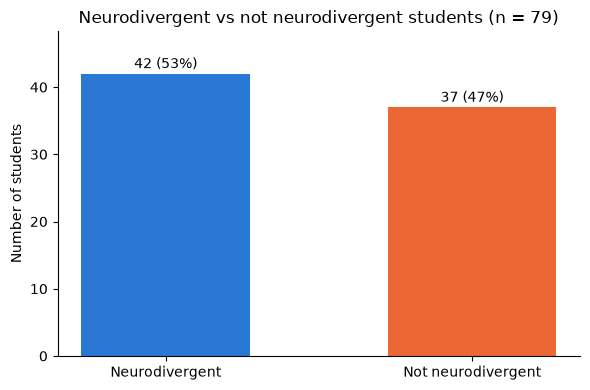

In [30]:
ND_COLOR = "#2a78d6"
NON_ND_COLOR = "#eb6834"

# Column 9 is multi-select: anyone who ticked a "neurodivergent" option (diagnosed or self-identified) counts as ND
df["neurodivergent"] = df["9"].str.contains("neurodivergent", case=False, na=False)
df["nd_group"] = df["neurodivergent"].map({True: "Neurodivergent", False: "Not neurodivergent"})

nd_counts = df["nd_group"].value_counts().reindex(["Neurodivergent", "Not neurodivergent"])
display(nd_counts)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(nd_counts.index, nd_counts.values, color=[ND_COLOR, NON_ND_COLOR], width=0.55)
for bar, n in zip(bars, nd_counts.values):
    ax.annotate(f"{n} ({n / nd_counts.sum():.0%})", (bar.get_x() + bar.get_width() / 2, n),
                xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_ylabel("Number of students")
ax.set_title(f"Neurodivergent vs not neurodivergent students (n = {nd_counts.sum()})")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, nd_counts.max() * 1.15)
plt.tight_layout()
plt.show()

### Diagnosed vs self-identified neurodivergent students

**Columns used**
- Only the **42 neurodivergent students** from the previous chart.
- Column 9, split into:
  - **Diagnosed**: ticked *Diagnosed neurodivergent*. This includes 4 students who also ticked *Self identified*, because they do have a medical diagnosis.
  - **Self-identified only**: ticked *Self identified neurodivergent (no formal diagnosis)* and not *Diagnosed*.
- Column 10, *"Which of the following apply to you?"* (more than one answer allowed).

**What the graph shows**
- **Left:** how many neurodivergent students are diagnosed vs self-identified.
- **Right:** the **% of students in each group** who ticked each condition, with the number of students next to the bar. Percentages are used so the two groups can be compared although they are different sizes. They add up to more than 100% because students could tick several conditions.

**Conclusions**
- **Most neurodivergent students have a formal diagnosis**: 25 (60%) are diagnosed and 17 (40%) self-identified.
- **ADHD is the most common condition in both groups** (72% of diagnosed, 53% of self-identified students), followed by **anxiety** (44% and 53%) and **ASD** (32% and 29%).
- **Depression is much more common among diagnosed students** (32% vs 12%).
- **5 of the 17 self-identified students (29%) ticked *Not sure***: they feel neurodivergent but do not know which condition applies.

**Limits**
- Column 10 mixes neurodevelopmental conditions (ADHD, ASD, dyslexia…) with mental health conditions (anxiety, depression, PTSD…). A student counted as "diagnosed" may have a diagnosis for only one of the conditions they ticked.

,students
diagnosis,
Diagnosed,25
Self-identified only,17


students                       \
diagnosis                            Diagnosed Self-identified only   
ADHD                                        18                    9   
Anxiety Disorder                            11                    9   
ASD                                          8                    5   
Depression Disorder                          8                    2   
OCD                                          1                    3   
APD                                          2                    1   
Dyslexia                                     3                    0   
PTSD                                         1                    2   
Bipolar Disorder                             2                    0   
Sensory Processing Differences (SPD)         2                    0   
BPD                                          1                    0   
Dyspraxia / DCD                              1                    0   
Not sure                                     0                    5   

                                     % of group                       
diagnosis                             Diagnosed Self-identified only  
ADHD                                       72.0                 53.0  
Anxiety Disorder                           44.0                 53.0  
ASD                                        32.0                 29.0  
Depression Disorder                        32.0                 12.0  
OCD                                         4.0                 18.0  
APD                                         8.0                  6.0  
Dyslexia                                   12.0                  0.0  
PTSD                                        4.0                 12.0  
Bipolar Disorder                            8.0                  0.0  
Sensory Processing Differences (SPD)        8.0                  0.0  
BPD                                         4.0                  0.0  
Dyspraxia / DCD                             4.0                  0.0  
Not sure                                    0.0                 29.0

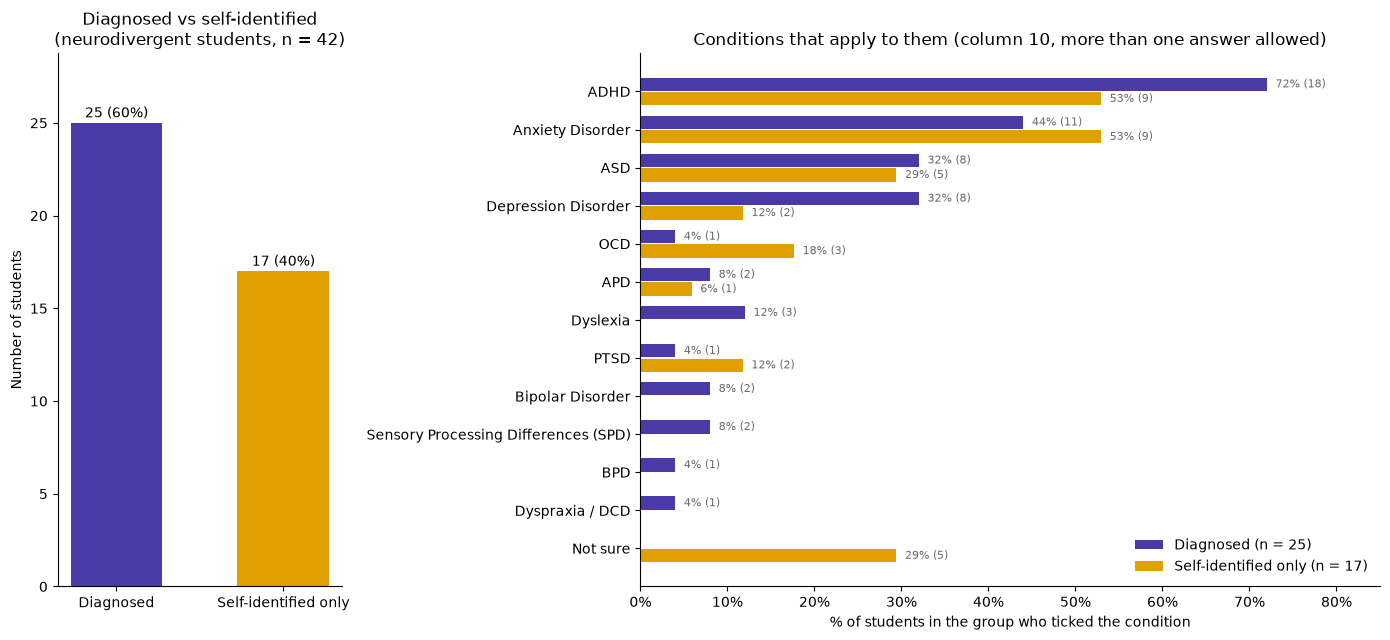

In [31]:
DIAG_COLOR = "#4a3aa7"
SELF_COLOR = "#e0a100"
DIAG_ORDER = ["Diagnosed", "Self-identified only"]

nd = df[df["neurodivergent"]].copy()
# Anyone who ticked "Diagnosed" counts as diagnosed, even if they also ticked "Self identified"
nd["diagnosis"] = nd["9"].str.contains("Diagnosed", na=False).map({True: "Diagnosed", False: "Self-identified only"})
diag_counts = nd["diagnosis"].value_counts().reindex(DIAG_ORDER)
group_sizes = diag_counts.to_dict()

# Column 10 is multi-select: one True/False column per condition
conditions = nd["10"].str.get_dummies(sep=";")
conditions.columns = conditions.columns.str.split(" – ").str[0]  # "ADHD – Attention Deficit..." -> "ADHD"
cond_counts = conditions.groupby(nd["diagnosis"]).sum().T.reindex(columns=DIAG_ORDER)
cond_pct = cond_counts / diag_counts
# Most common conditions first; "Not sure" / "None" are kept at the bottom
other = [c for c in ["Not sure", "None"] if c in cond_counts.index]
order = cond_counts.drop(other).sum(axis=1).sort_values(ascending=False).index.tolist() + other
cond_counts, cond_pct = cond_counts.loc[order], cond_pct.loc[order]

display(diag_counts.to_frame("students"))
display(pd.concat({"students": cond_counts, "% of group": (cond_pct * 100).round(0)}, axis=1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 2.6]})

# Left: diagnosed vs self-identified
bars = ax1.bar(DIAG_ORDER, diag_counts.values, color=[DIAG_COLOR, SELF_COLOR], width=0.55)
for bar, n in zip(bars, diag_counts.values):
    ax1.annotate(f"{n} ({n / diag_counts.sum():.0%})", (bar.get_x() + bar.get_width() / 2, n),
                 xytext=(0, 4), textcoords="offset points", ha="center")
ax1.set_ylabel("Number of students")
ax1.set_ylim(0, diag_counts.max() * 1.15)
ax1.set_title(f"Diagnosed vs self-identified\n(neurodivergent students, n = {diag_counts.sum()})")
ax1.spines[["top", "right"]].set_visible(False)

# Right: % of each group with each condition
y = np.arange(len(order))
h = 0.38
for offset, group, color in [(-h / 2, "Diagnosed", DIAG_COLOR), (h / 2, "Self-identified only", SELF_COLOR)]:
    ax2.barh(y + offset, cond_pct[group], height=h - 0.03, color=color,
             label=f"{group} (n = {group_sizes[group]})")
    for yi, pct, n in zip(y + offset, cond_pct[group], cond_counts[group]):
        if n > 0:
            ax2.text(pct + 0.01, yi, f"{pct:.0%} ({n})", va="center", fontsize=8, color="dimgrey")
ax2.set_yticks(y, order)
ax2.invert_yaxis()
ax2.set_xlim(0, 0.85)
ax2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax2.set_xlabel("% of students in the group who ticked the condition")
ax2.set_title("Conditions that apply to them (column 10, more than one answer allowed)")
ax2.legend(frameon=False, loc="lower right")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


### When students were diagnosed, by condition

**Columns used**
- Column 11, *"When did you receive your diagnosis, if any?"*: the **36 students** who answered *Before vet school* or *During vet school*.
- This group is not exactly the 25 "diagnosed neurodivergent" students above. Column 11 asks about *any* diagnosis, so it also includes 9 students who did not identify as neurodivergent (most likely diagnosed with anxiety or depression) and 2 self-identified students who answered *During vet school*.
- Column 10 (conditions). *Not sure* answers are left out, since they are not a condition, but the percentages are still out of everyone in the timing group.

**What the graph shows**
- **Left:** how many students were diagnosed before vs during vet school.
- **Right:** for each condition, the **% of students in each timing group** who ticked it, with the number of students next to each bar. Percentages add up to more than 100% because students could tick several conditions.

**Conclusions**
- **Almost half of the diagnoses came during vet school**: 17 of 36 students (47%) were diagnosed during their studies, 19 (53%) before.
- **Students diagnosed before vet school more often ticked ADHD (63% vs 47%) and depression (53% vs 29%).**
- **Students diagnosed during vet school more often ticked anxiety (53% vs 37%) and ASD (29% vs 16%).** This fits the idea that the demands of vet school bring some difficulties to light, but the groups are small (17–19 students).

**Limits**
- The survey asks *when* the diagnosis was received, but not *which* condition it was for. A student diagnosed during vet school with ADHD may also tick anxiety without an anxiety diagnosis, so this chart shows which conditions are common in each group, not the exact timing of each diagnosis.

11,Before vet school,During vet school
9,,
Diagnosed neurodivergent (you have received a medical diagnosis),11,10
Diagnosed neurodivergent (you have received a medical diagnosis);Self identified neurodivergent (no formal diagnosis),1,3
I haven't thought much of it.,4,0
Neurotypical,3,1
Neurotypical;I haven't thought much of it.,0,1
Self identified neurodivergent (no formal diagnosis),0,2


,students
11,
Before vet school,19
During vet school,17


students                    \
11                                   Before vet school During vet school   
ADHD                                                12                 8   
Anxiety Disorder                                     7                 9   
Depression Disorder                                 10                 5   
ASD                                                  3                 5   
Dyslexia                                             4                 1   
APD                                                  1                 1   
Bipolar Disorder                                     0                 2   
PTSD                                                 1                 1   
Sensory Processing Differences (SPD)                 1                 1   
BPD                                                  1                 0   
Dyspraxia / DCD                                      1                 0   
OCD                                                  0                 1   

                                            % of group                    
11                                   Before vet school During vet school  
ADHD                                              63.0              47.0  
Anxiety Disorder                                  37.0              53.0  
Depression Disorder                               53.0              29.0  
ASD                                               16.0              29.0  
Dyslexia                                          21.0               6.0  
APD                                                5.0               6.0  
Bipolar Disorder                                   0.0              12.0  
PTSD                                               5.0               6.0  
Sensory Processing Differences (SPD)               5.0               6.0  
BPD                                                5.0               0.0  
Dyspraxia / DCD                                    5.0               0.0  
OCD                                                0.0               6.0

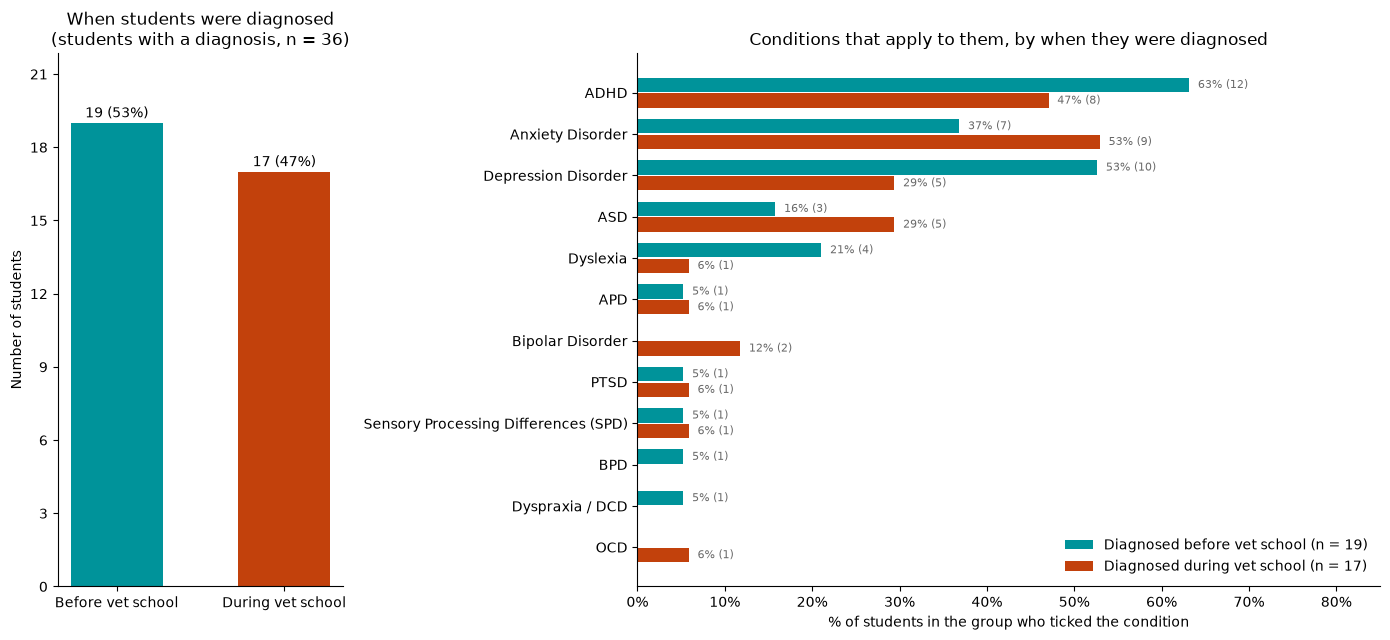

In [32]:
BEFORE_COLOR = "#00939a"
DURING_COLOR = "#c2410c"
TIMING_ORDER = ["Before vet school", "During vet school"]

diagnosed = df[df["11"].isin(TIMING_ORDER)].copy()
timing_counts = diagnosed["11"].value_counts().reindex(TIMING_ORDER)
display(pd.crosstab(diagnosed["9"], diagnosed["11"]))  # who is in each timing group

# Column 10 is multi-select: one True/False column per condition
timing_conditions = diagnosed["10"].str.get_dummies(sep=";")
timing_conditions.columns = timing_conditions.columns.str.split(" – ").str[0]
timing_counts_cond = timing_conditions.groupby(diagnosed["11"]).sum().T.reindex(columns=TIMING_ORDER)
timing_pct = timing_counts_cond / timing_counts
# "Not sure" / "None" are not conditions, so they are left out; most common conditions first
timing_counts_cond = timing_counts_cond.drop(["Not sure", "None"], errors="ignore")
timing_pct = timing_pct.drop(["Not sure", "None"], errors="ignore")
order = timing_counts_cond.sum(axis=1).sort_values(ascending=False).index.tolist()
timing_counts_cond, timing_pct = timing_counts_cond.loc[order], timing_pct.loc[order]

display(timing_counts.to_frame("students"))
display(pd.concat({"students": timing_counts_cond, "% of group": (timing_pct * 100).round(0)}, axis=1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 2.6]})

# Left: diagnosed before vs during vet school
bars = ax1.bar(TIMING_ORDER, timing_counts.values, color=[BEFORE_COLOR, DURING_COLOR], width=0.55)
for bar, n in zip(bars, timing_counts.values):
    ax1.annotate(f"{n} ({n / timing_counts.sum():.0%})", (bar.get_x() + bar.get_width() / 2, n),
                 xytext=(0, 4), textcoords="offset points", ha="center")
ax1.set_ylabel("Number of students")
ax1.set_ylim(0, timing_counts.max() * 1.15)
ax1.yaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=True))
ax1.set_title(f"When students were diagnosed\n(students with a diagnosis, n = {timing_counts.sum()})")
ax1.spines[["top", "right"]].set_visible(False)

# Right: % of each timing group with each condition
y = np.arange(len(order))
h = 0.38
for offset, group, color in [(-h / 2, "Before vet school", BEFORE_COLOR), (h / 2, "During vet school", DURING_COLOR)]:
    ax2.barh(y + offset, timing_pct[group], height=h - 0.03, color=color,
             label=f"Diagnosed {group.lower()} (n = {timing_counts[group]})")
    for yi, pct, n in zip(y + offset, timing_pct[group], timing_counts_cond[group]):
        if n > 0:
            ax2.text(pct + 0.01, yi, f"{pct:.0%} ({n})", va="center", fontsize=8, color="dimgrey")
ax2.set_yticks(y, order)
ax2.invert_yaxis()
ax2.set_xlim(0, 0.85)
ax2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax2.set_xlabel("% of students in the group who ticked the condition")
ax2.set_title("Conditions that apply to them, by when they were diagnosed")
ax2.legend(frameon=False, loc="lower right")
ax2.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


## How common are depression and anxiety

### Depression and anxiety screening (PHQ-9 and GAD-7)

**Columns used**
- **Depression: PHQ-9**, 9 items (columns 70–78), each scored 0–3, so totals run from 0 to 27.
- **Anxiety: GAD-7**, 7 items (columns 79–85), each scored 0–3, so totals run from 0 to 21.
- Both ask about the **last 2 weeks**.
- Missing answers: the 5 students who skipped one PHQ-9 item get the average of their other 8 items in its place (prorating). The 2 students who skipped the whole PHQ-9 are left out, so the depression graph has 77 students and the anxiety graph 79.

**What the graph shows**
- The **line** shows how many students got each total score. Each graph is read separately: a student can have one condition, both, or neither.
- The **shaded area** covers scores of 10 or more, the standard cut-off for at least *moderate* symptoms on both questionnaires. The count of students in that area is written at the top of each graph.
- The tables above the plot split each score into its standard severity bands.

**Conclusions**
- **Depression and anxiety symptoms are very common.** 77% of students (59 of 77) score 10 or more on the PHQ-9 and 73% (58 of 79) on the GAD-7.
- **Many are in the most severe bands**: 36 students (47%) have *moderately severe* or *severe* depression symptoms (15 or more), and 30 (38%) have *severe* anxiety symptoms (15 or more).
- The average scores (depression 14.7, anxiety 12.3) are both inside the *moderate* band.

**Limits**
- The PHQ-9 and GAD-7 are screening tools, not a diagnosis. A high score means "should be assessed by a professional", not "has a depressive or anxiety disorder".
- Students with more symptoms may have been more motivated to answer a survey about mental health, which would push these numbers up.

PHQ-9: 5 students prorated (1 item missing), 2 left out (whole questionnaire skipped)
Depression (PHQ-9): n = 77, mean = 14.7, median = 14, score ≥ 10: 59 (77%)


,students
phq9_total,
Minimal (0-4),2
Mild (5-9),16
Moderate (10-14),23
Moderately severe (15-19),17
Severe (20-27),19


Anxiety (GAD-7): n = 79, mean = 12.3, median = 13, score ≥ 10: 58 (73%)


,students
gad7_total,
Minimal (0-4),9
Mild (5-9),12
Moderate (10-14),28
Severe (15-21),30


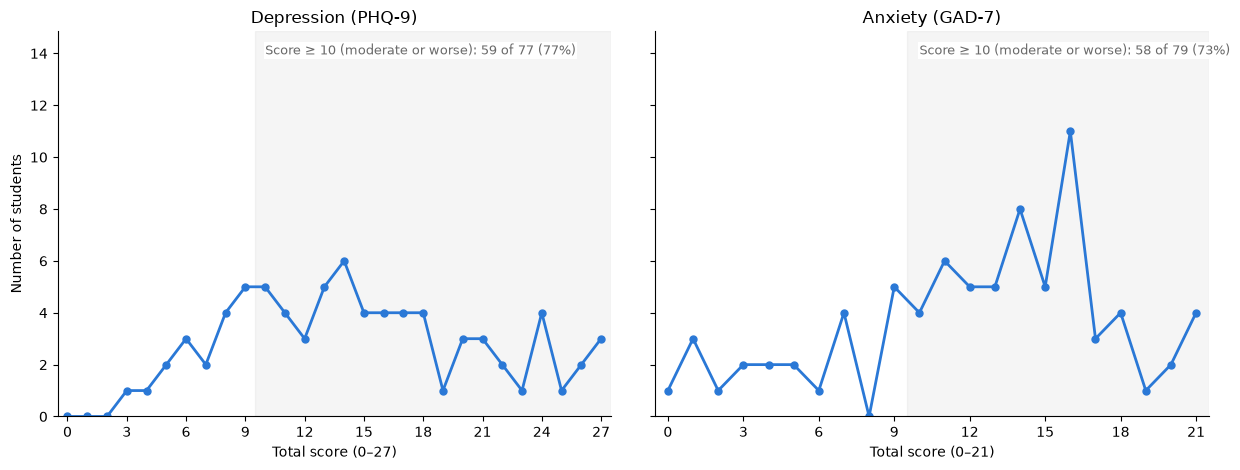

In [33]:
def screening_total(items):
    # Prorate when at most one item is missing; otherwise leave the score empty
    answered = items.notna().sum(axis=1)
    total = items.mean(axis=1) * items.shape[1]
    return total.where(answered >= items.shape[1] - 1).round()

print(f"PHQ-9: {(df[PHQ9_COLS].isna().sum(axis=1) == 1).sum()} students prorated (1 item missing), "
      f"{(df[PHQ9_COLS].isna().sum(axis=1) > 1).sum()} left out (whole questionnaire skipped)")

df["phq9_total"] = screening_total(df[PHQ9_COLS])
df["gad7_total"] = screening_total(df[GAD7_COLS])

PHQ9_BANDS = ([-1, 4, 9, 14, 19, 27], ["Minimal (0-4)", "Mild (5-9)", "Moderate (10-14)", "Moderately severe (15-19)", "Severe (20-27)"])
GAD7_BANDS = ([-1, 4, 9, 14, 21], ["Minimal (0-4)", "Mild (5-9)", "Moderate (10-14)", "Severe (15-21)"])

screenings = [
    ("Depression (PHQ-9)", "phq9_total", 27, PHQ9_BANDS),
    ("Anxiety (GAD-7)", "gad7_total", 21, GAD7_BANDS),
]

# Shared y-axis so the two line heights can be compared directly
y_max = max(df[col].value_counts().max() for _, col, _, _ in screenings) * 1.35

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (name, col, max_score, (bins, labels)) in zip(axes, screenings):
    scores = df[col].dropna()
    n = len(scores)
    positive = (scores >= 10).sum()

    print(f"{name}: n = {n}, mean = {scores.mean():.1f}, median = {scores.median():.0f}, "
          f"score ≥ 10: {positive} ({positive / n:.0%})")
    display(pd.cut(scores, bins=bins, labels=labels).value_counts().sort_index().to_frame("students"))

    # Number of students at every possible score, including scores nobody got
    counts = scores.value_counts().reindex(range(max_score + 1), fill_value=0)
    ax.axvspan(9.5, max_score + 0.5, color="grey", alpha=0.08)
    ax.text(10, y_max * 0.94, f"Score ≥ 10 (moderate or worse): {positive} of {n} ({positive / n:.0%})",
            fontsize=9, color="dimgrey", bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.plot(counts.index, counts.values, color=ND_COLOR, linewidth=2, marker="o", markersize=5)

    ax.set_title(name)
    ax.set_xlabel(f"Total score (0–{max_score})")
    ax.set_xticks(range(0, max_score + 1, 3))
    ax.set_xlim(-0.5, max_score + 0.5)
    ax.set_ylim(0, y_max)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Number of students")
plt.tight_layout()
plt.show()

## High expectations and workload in veterinary school environments


### Academic overwhelm score

**Columns used**
- Two questions answered from 1 (strongly disagree) to 5 (strongly agree):
  - Column 26: *"I feel overwhelmed by the volume of academic **expectations** in my program."*
  - Column 27: *"I feel overwhelmed by the volume of academic **workload** in my program."*
- The **overwhelm score is the average of the two answers**. For example, a student who answered 4 and 5 gets 4.5. 4 students skipped column 27, so their score is just their column 26 answer.

**Method: Spearman correlation (ρ)**
- Checks that the two questions can be averaged into one score: they should rise and fall together. See *Statistical methods* for how ρ works.

**Reading the numbers: ρ = 0.73 (p < 0.001)**
- The two numbers answer different questions. **ρ = 0.73 is the strength of the link**; **p < 0.001 is how sure we can be that the link is not chance.**
- **ρ = 0.73**: the 75 students who answered both questions were ranked on each one, and the two rankings are very similar. On the −1 to +1 scale this is a **strong** link (0.5 is already strong). ρ² ≈ 0.53, so about half of the variation in one answer goes together with the other.
- **p < 0.001** (exact value 1.8 × 10⁻¹³): if the two questions were really unrelated, a sample of 75 students would almost never show a correlation this strong. Converting ρ to the test statistic gives t = 0.73 × √(73 / (1 − 0.73²)) ≈ 9.1, far beyond the ≈ 2 needed for p < 0.05.
- Together: the link is both strong and almost certainly real, so the two questions measure nearly the same feeling and can be combined.

**What the graph shows**
- The number of students at each overwhelm score.
- A score of **4 or more** (shaded area) means the student agrees, on average, that they feel overwhelmed. These students form the **high overwhelm** group in the next charts.

**Conclusions**
- **Almost every student feels overwhelmed**: 68 of 79 (86%) score 4 or more, and only 11 score below 4.
- **Half of all students (40, 51%) have the maximum score of 5**: 39 answered *strongly agree* to both questions.

Overwhelm score: n = 79, average = 4.39, score ≥ 4: 68 (86%)
Correlation between item 26 and item 27: Spearman ρ = 0.73, p = 1.8e-13
Maximum score of 5: 40 students (39 answered 5 to both questions)


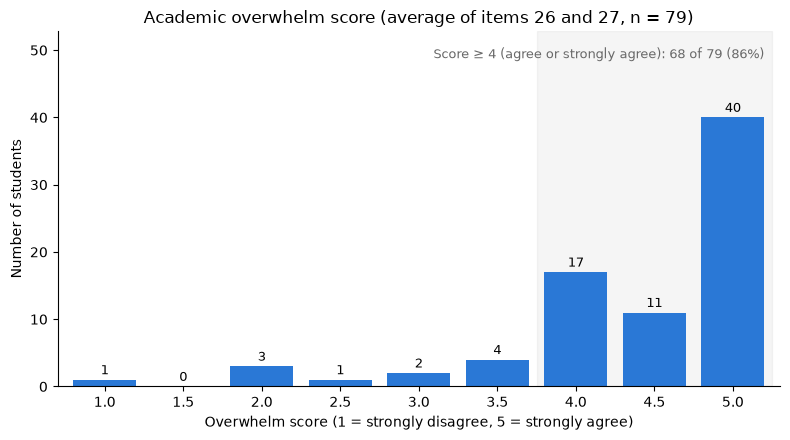

In [34]:
OVERWHELM_COLS = ["26", "27"]  # overwhelmed by academic expectations / by academic workload, each 1-5

# Overwhelm score = average of the two answers (4 students skipped item 27, so their score is item 26 alone)
df["overwhelm"] = df[OVERWHELM_COLS].mean(axis=1)

scores = df["overwhelm"].dropna()
n = len(scores)
high = (scores >= 4).sum()
rho, rho_p = stats.spearmanr(df["26"], df["27"], nan_policy="omit")
print(f"Overwhelm score: n = {n}, average = {scores.mean():.2f}, score ≥ 4: {high} ({high / n:.0%})")
print(f"Correlation between item 26 and item 27: Spearman ρ = {rho:.2f}, p = {rho_p:.1e}")
print(f"Maximum score of 5: {(scores == 5).sum()} students "
      f"({((df['26'] == 5) & (df['27'] == 5)).sum()} answered 5 to both questions)")

# Number of students at every possible score, including scores nobody got
levels = [1 + 0.5 * i for i in range(9)]
counts = scores.value_counts().reindex(levels, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axvspan(3.75, 5.25, color="grey", alpha=0.08)
ax.text(5.2, counts.max() * 1.22, f"Score ≥ 4 (agree or strongly agree): {high} of {n} ({high / n:.0%})",
        fontsize=9, color="dimgrey", ha="right")
bars = ax.bar(counts.index, counts.values, width=0.4, color=ND_COLOR)
for bar, c in zip(bars, counts.values):
    ax.annotate(str(c), (bar.get_x() + bar.get_width() / 2, c),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)

ax.set_title(f"Academic overwhelm score (average of items 26 and 27, n = {n})")
ax.set_xlabel("Overwhelm score (1 = strongly disagree, 5 = strongly agree)")
ax.set_ylabel("Number of students")
ax.set_xticks(levels)
ax.set_xlim(0.7, 5.3)
ax.set_ylim(0, counts.max() * 1.32)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Average answers by overwhelm group

**Columns used**
- The **high overwhelm** group (score ≥ 4, 68 students) and the **low/moderate overwhelm** group (score < 4, 11 students), from the previous chart.
- Four questions answered from 1 to 5:
  - **Feeling anxious or overwhelmed (63)**, **Feeling depressed (64)**, **Stress level (48)**: a higher number means more often or more intense.
  - **Mental state since starting uni (51)**: 1 = greatly worsened, 3 = no change, 5 = greatly improved. A **lower** number means the student's mental state has **got worse** since starting vet school.

**What the graph shows**
- The **average answer** of each group to each question.

**Method: Mann-Whitney U test**
- Checks whether one group tends to give higher answers than the other. It is used instead of a t-test because the answers are on a 1–5 scale, not exact measurements. p < 0.05 = significant.

**Reading the numbers**
- The averages show **how big** each difference is; the p-value shows **whether it could be chance**.
- **p = 0.003** (feeling anxious or overwhelmed, 4.2 vs 3.5): if overwhelm made no difference, a gap this large would appear in only about 3 of 1,000 samples of this size. Significant.
- **p = 0.011** (stress) and **p = 0.014** (mental state since uni): about 1 in 100. Significant.
- **p = 0.084** (feeling depressed, 3.3 vs 2.6): a gap this large would appear in about 8 of 100 samples by chance alone. That is above the 0.05 threshold, so it is **not significant**. It does **not** show that overwhelm has no link with depression: the low group has only 11 students, so only large gaps can reach significance.

**Conclusions**
- **Highly overwhelmed students feel anxious or overwhelmed more often** (4.2 vs 3.5, p = 0.003) and have **higher stress** (4.3 vs 3.7, p = 0.011).
- **Highly overwhelmed students say their mental state has got worse since starting university** (2.0 vs 2.8, p = 0.014). An average of 2.0 means *worsened*, while 2.8 is close to *no change*.
- They also **feel depressed more often** (3.3 vs 2.6), but this difference is not significant (p = 0.084).

**Limits**
- The low/moderate group has only 11 students, so only large differences can be detected. The next chart uses the full score instead of two groups.
- Question 63 contains the word *overwhelmed*, so part of its link with the overwhelm score is because they ask about the same feeling.
- Column 51 is the student's own memory of how they felt before university, not a measurement taken at the time.

High overwhelm: 68 students, low/moderate overwhelm: 11 students


,question,low/moderate overwhelm average,high overwhelm average,p-value
0,Feeling anxious or overwhelmed (63),3.455,4.206,0.003
1,Feeling depressed (64),2.636,3.265,0.084
2,Stress level (48),3.727,4.324,0.011
3,"Mental state since uni (51) 1 = greatly worse,...",2.818,2.015,0.014


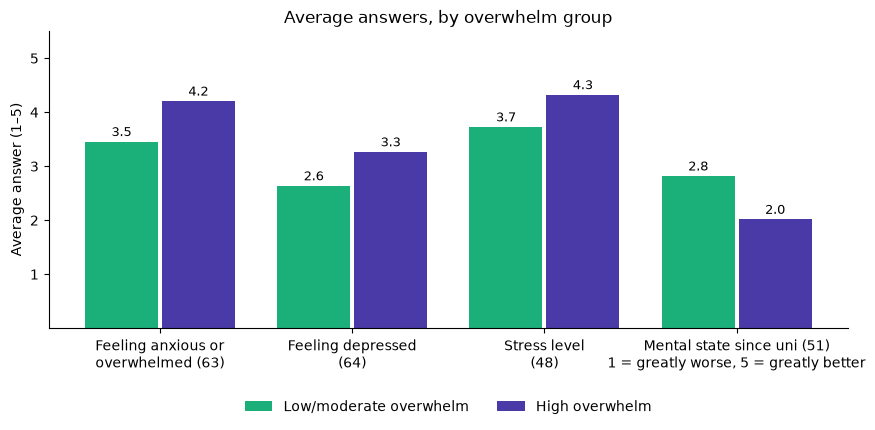

In [35]:
HIGH_COLOR = "#4a3aa7"
LOW_COLOR = "#1baf7a"

# High overwhelm = overwhelm score of 4 or more (agrees, on average, that they feel overwhelmed)
df["high_overwhelm"] = df["overwhelm"] >= 4
print(f"High overwhelm: {df['high_overwhelm'].sum()} students, "
      f"low/moderate overwhelm: {(~df['high_overwhelm']).sum()} students")

QUESTIONS = [
    ("Feeling anxious or\noverwhelmed (63)", "63"),
    ("Feeling depressed\n(64)", "64"),
    ("Stress level\n(48)", "48"),
    ("Mental state since uni (51)\n1 = greatly worse, 5 = greatly better", "51"),
]

rows = []
for name, col in QUESTIONS:
    low = df.loc[~df["high_overwhelm"], col].dropna()
    high = df.loc[df["high_overwhelm"], col].dropna()
    # Mann-Whitney U test: do the high-overwhelm students tend to give higher answers?
    rows.append({
        "question": name.replace("\n", " "),
        "low/moderate overwhelm average": low.mean(),
        "high overwhelm average": high.mean(),
        "p-value": stats.mannwhitneyu(high, low).pvalue,
    })
averages = pd.DataFrame(rows)
display(averages.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = range(len(QUESTIONS))
for offset, col, color, label in [(-0.2, "low/moderate overwhelm average", LOW_COLOR, "Low/moderate overwhelm"),
                                  (0.2, "high overwhelm average", HIGH_COLOR, "High overwhelm")]:
    bars = ax.bar([i + offset for i in x], averages[col], width=0.38, color=color, label=label)
    for bar, value in zip(bars, averages[col]):
        ax.annotate(f"{value:.1f}", (bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)

ax.set_xticks(list(x), [name for name, _ in QUESTIONS])
ax.set_ylabel("Average answer (1–5)")
ax.set_ylim(0, 5.5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_title("Average answers, by overwhelm group")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### How strongly each outcome is linked to feeling overwhelmed

**Columns used**
- The **full overwhelm score (1–5)** for every student, instead of two groups, so no information is lost and the small low-overwhelm group no longer matters.
- Six outcomes: the PHQ-9 and GAD-7 totals, and questions 63, 64, 48 and 51 from the previous chart.

**What the graph shows**
- One bar per outcome: its **Spearman correlation** with the overwhelm score.
  - **Positive bar**: the more overwhelmed the student, the higher the outcome.
  - **Negative bar**: the more overwhelmed the student, the lower the outcome.

**Method: Spearman correlation (ρ)**
- Measures whether one thing tends to go up when another goes up, from −1 to +1. Around 0.1 is weak, 0.3 moderate and 0.5 strong. p < 0.05 = significant.

**Reading the numbers**
- **ρ = 0.38 to 0.45** (PHQ-9, feeling anxious or overwhelmed, feeling depressed, stress): **moderate** links. ρ² ≈ 0.14–0.20, so overwhelm goes together with about 15–20% of the variation in these outcomes. The rest depends on other things.
- **ρ = −0.43** (mental state since uni): the same strength, but negative. The more overwhelmed, the *lower* the answer, which on this question means *more worsened*.
- **ρ = 0.26, p = 0.023** (GAD-7): a **weak** link (ρ² ≈ 0.07), but still significant: with 79 students, a correlation needs to be about 0.22 to reach p < 0.05.
- **p < 0.001** for all other outcomes: with 79 students, links of this size would almost never appear by chance.

**Conclusions**
- **Every outcome is significantly linked to feeling overwhelmed** (all p < 0.05).
- **The links are moderate** for depression (PHQ-9, ρ = 0.38), feeling anxious or overwhelmed (0.44), feeling depressed (0.42) and stress (0.45). The link with **anxiety (GAD-7) is weaker** (ρ = 0.26).
- **The more overwhelmed the student, the more their mental state has worsened since starting university** (ρ = −0.43, a moderate link).
- Students who feel more overwhelmed by the workload and expectations of vet school also report more anxiety, depression and stress.

**Limits**
- This is a **link, not proof of cause**: it is also possible that students who were already anxious or depressed experience the same workload as more overwhelming.
- Question 63 partly overlaps with the overwhelm score (see the previous chart), so its correlation is probably a bit inflated.

,outcome,Spearman ρ,p-value
0,Anxiety (GAD-7),0.256,0.023
1,Depression (PHQ-9),0.376,0.001
2,Feeling anxious or overwhelmed (63),0.443,0.000
3,Feeling depressed (64),0.425,0.000
4,Stress level (48),0.448,0.000
5,Mental state since starting uni (51),-0.433,0.000


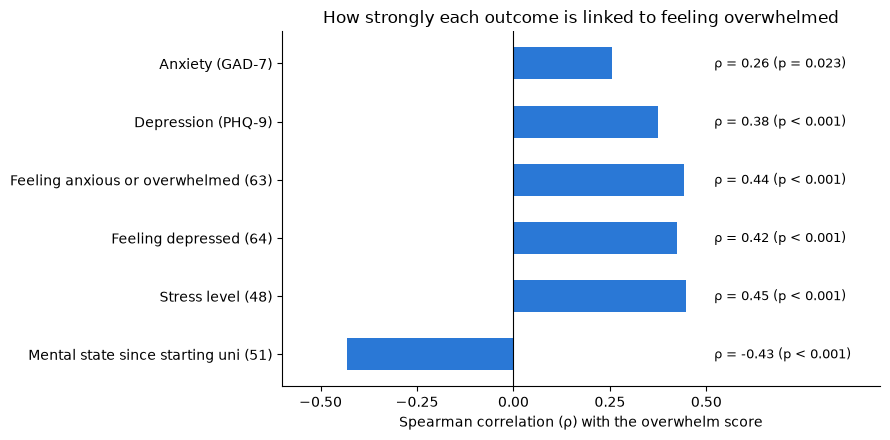

In [36]:
# Spearman correlation: does each outcome go up (or down) as the overwhelm score goes up?
ALL_OUTCOMES = [
    ("Anxiety (GAD-7)", "gad7_total"),
    ("Depression (PHQ-9)", "phq9_total"),
    ("Feeling anxious or overwhelmed (63)", "63"),
    ("Feeling depressed (64)", "64"),
    ("Stress level (48)", "48"),
    ("Mental state since starting uni (51)", "51"),
]

rows = []
for name, col in ALL_OUTCOMES:
    rho, p = stats.spearmanr(df["overwhelm"], df[col], nan_policy="omit")
    rows.append({"outcome": name, "Spearman ρ": rho, "p-value": p})
correlations = pd.DataFrame(rows)
display(correlations.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
y = range(len(ALL_OUTCOMES))
ax.barh(list(y), correlations["Spearman ρ"], height=0.55, color=ND_COLOR)
for i, (rho, p) in enumerate(zip(correlations["Spearman ρ"], correlations["p-value"])):
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    ax.text(0.52, i, f"ρ = {rho:.2f} ({p_text})", va="center", fontsize=9)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(list(y), correlations["outcome"])
ax.invert_yaxis()
ax.set_xlim(-0.6, 0.95)
ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
ax.set_xlabel("Spearman correlation (ρ) with the overwhelm score")
ax.set_title("How strongly each outcome is linked to feeling overwhelmed")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Distress and wellbeing by year of study

### Depression and anxiety scores by year of study

**Columns used**
- Column 8 (year of study), combined into 4 groups: **early years** (1–2), **middle years** (3–4), **final year** (5+) and **graduates**. Years are combined because years 3 and 4 alone have only 8 and 6 students, too few to compare.
- PHQ-9 (depression, 0–27) and GAD-7 (anxiety, 0–21) totals from the screening chart.

**What the graph shows**
- Left: **depression** score. Right: **anxiety** score. A higher score means more symptoms.
- Each **bar** is the **average score** of the group (graduates in grey). Each **grey dot** is one student.
- The **shaded area** marks a score of 10 or more (at least *moderate* symptoms).
- Under each bar: the number of students (n), the average score and the **% of students who score 10 or more**.

**Method: Mann-Whitney U test**
- Checks whether one group tends to have higher scores than another. p < 0.05 = significant. Three comparisons are made for each score:
  1. Middle-year students vs all other students.
  2. Final-year students vs all other students.
  3. Graduates vs all current students.

**Reading the numbers**
- **p = 0.010** (depression, graduates 10.3 vs current students 15.4): a gap this big would appear by chance in only about 1 in 100 samples. Significant, and a large difference (about 5 points on a 0–27 scale, about one severity band).
- **p = 0.088** (anxiety, graduates 8.9 vs 12.7): the gap is also large, but with only 10 graduates it could appear by chance about 9 times in 100. Not significant, but it points the same way as depression.
- **p = 0.938** (depression, middle years 15.4 vs others 15.4): the two groups are practically identical; almost any random split would give a gap at least this big.
- The averages are shown to make the size of the difference easy to see; the Mann-Whitney test itself compares the **ranks** of all students in the two groups.

**Conclusions**
- **Depression and anxiety are high in every year of study**: 67–84% of current students have at least moderate depression and 57–88% at least moderate anxiety.
- **Middle-year and final-year students have similar scores to the other students.** Depression: middle 15.4 vs 15.4, final 13.7 vs 15.8. Anxiety: middle 11.7 vs 13.0, final 13.4 vs 12.5. None of these differences is significant.
- **Graduates have significantly less depression** than current students (average 10.3 vs 15.4, p = 0.010). They also have less anxiety (8.9 vs 12.7), but this difference is not significant (p = 0.088).

**Limits**
- Only 10 graduates answered, and each student answered once: this compares different people in different years, not the same students over time.
- Graduates who left vet school with more distress may have been less (or more) likely to answer, which would change the comparison.

,students
year_group,
Early years\n(1–2),38
Middle years\n(3–4),14
Final year\n(5+),17
Graduates\n,10


,score,comparison,group average,others average,p-value
0,Depression (PHQ-9),Middle years vs other students,15.357,15.358,0.938
1,Depression (PHQ-9),Final year vs other students,13.733,15.827,0.225
2,Depression (PHQ-9),Graduates vs all students,10.300,15.358,0.010
3,Anxiety (GAD-7),Middle years vs other students,11.714,13.000,0.346
4,Anxiety (GAD-7),Final year vs other students,13.353,12.538,0.525
5,Anxiety (GAD-7),Graduates vs all students,8.900,12.739,0.088


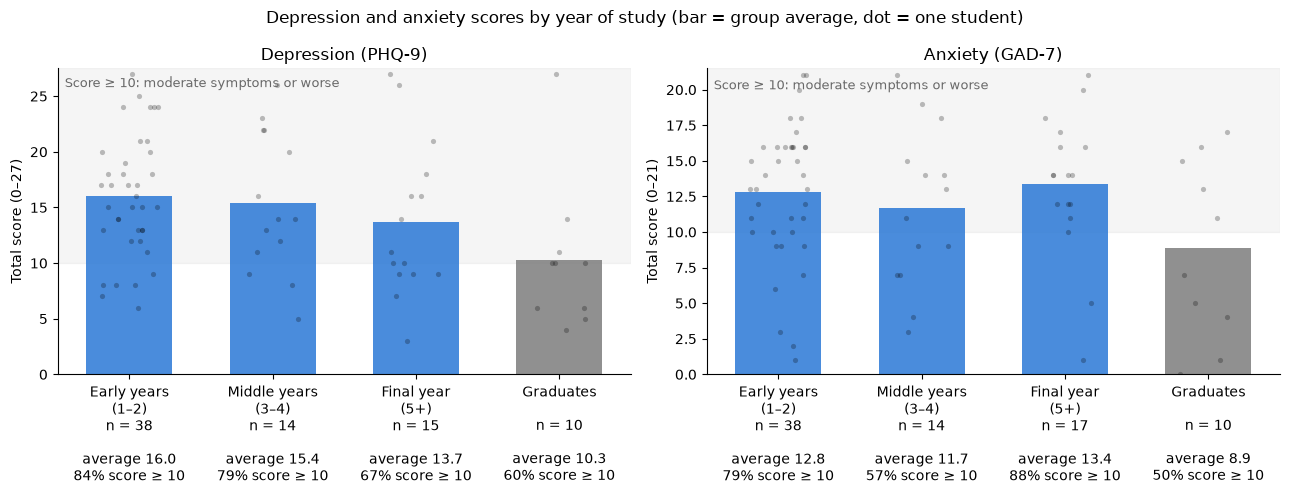

In [37]:
# Years are combined into 4 groups so that no group is too small to compare (years 3 and 4 alone have only 8 and 6 students)
YEAR_GROUPS = {"1": "Early years\n(1–2)", "2": "Early years\n(1–2)", "3": "Middle years\n(3–4)", "4": "Middle years\n(3–4)",
               "5+": "Final year\n(5+)", "Graduated": "Graduates\n"}
GROUP_ORDER = ["Early years\n(1–2)", "Middle years\n(3–4)", "Final year\n(5+)", "Graduates\n"]
GROUP_COLORS = [ND_COLOR, ND_COLOR, ND_COLOR, "#7d7d7d"]  # graduates in grey: they are no longer studying

df["year_group"] = df["8"].map(YEAR_GROUPS)
# Year as a number (1-5) for the trend test; graduates are left out because they are not a "year 6"
df["year_num"] = df["8"].map({"1": 1, "2": 2, "3": 3, "4": 4, "5+": 5})
students = df[df["8"] != "Graduated"]
graduates = df[df["8"] == "Graduated"]
display(df["year_group"].value_counts().reindex(GROUP_ORDER).to_frame("students"))

DISTRESS = [("Depression (PHQ-9)", "phq9_total", 27), ("Anxiety (GAD-7)", "gad7_total", 21)]

# Mann-Whitney U tests, one for each part of the theory
rows = []
for name, col, _ in DISTRESS:
    for question, group, others in [
        ("Middle years vs other students", students[students["8"].isin(["3", "4"])], students[~students["8"].isin(["3", "4"])]),
        ("Final year vs other students", students[students["8"] == "5+"], students[students["8"] != "5+"]),
        ("Graduates vs all students", graduates, students),
    ]:
        rows.append({"score": name, "comparison": question,
                     "group average": group[col].mean(), "others average": others[col].mean(),
                     "p-value": stats.mannwhitneyu(group[col].dropna(), others[col].dropna()).pvalue})
display(pd.DataFrame(rows).round(3))

rng = np.random.default_rng(0)  # fixed jitter so the dots land in the same place on every run
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, col, max_score) in zip(axes, DISTRESS):
    ax.axhspan(10, max_score + 0.5, color="grey", alpha=0.08)
    ax.text(-0.45, max_score - 0.2, "Score ≥ 10: moderate symptoms or worse", fontsize=9, color="dimgrey", va="top")
    tick_labels = []
    for i, (group, color) in enumerate(zip(GROUP_ORDER, GROUP_COLORS)):
        scores = df.loc[df["year_group"] == group, col].dropna()
        tick_labels.append(f"{group}\nn = {len(scores)}\n\naverage {scores.mean():.1f}\n{(scores >= 10).mean():.0%} score ≥ 10")
        # Bar = group average, faint dots = individual students
        ax.bar(i, scores.mean(), width=0.6, color=color, alpha=0.85)
        ax.scatter(i + rng.uniform(-0.2, 0.2, len(scores)), scores, s=14, color="black", alpha=0.25, linewidths=0)
    ax.set_xticks(range(len(GROUP_ORDER)), tick_labels)
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, max_score + 0.5)
    ax.set_ylabel(f"Total score (0–{max_score})")
    ax.set_title(name)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Depression and anxiety scores by year of study (bar = group average, dot = one student)")
plt.tight_layout()
plt.show()

### Daily wellbeing and lifestyle by year of study

**Columns used**
- Columns 41–47: seven lifestyle statements, answered from 1 (strongly disagree) to 5 (strongly agree).
- Column 48: overall stress level, from 1 to 5.
- Year groups from the previous chart.

**What the graph shows**
- Each box is the **% of students in that group who agree** (answered 4 or 5). Darker blue = more students agree.
- Example: 76% of final-year students agree that they eat regular meals, compared with 39% in the early years.
- The last row, **stress (48)**, shows the % of students with **high or very high stress** (4 or 5). It is set apart because here a *higher* % means *worse* wellbeing.

**Method: Spearman correlation (ρ)**
- Checks whether answers go **up or down as the year of study goes up** (year 1, 2, 3, 4, 5; graduates are left out because they are not a "year 6"). The result is written to the right of each row.
- **Positive** = students in higher years agree **more**. **Negative** = they agree **less**. Close to 0 = no change. Around 0.1 is weak, 0.3 moderate and 0.5 strong.
- p < 0.05 = significant (shown in **bold**).

**Reading the numbers**
- **Eat regular meals: ρ = +0.26, p = 0.034.** A **weak** positive trend (ρ² ≈ 0.07): students in later years agree a bit more often. With 69 current students, a correlation needs to be about 0.24 to reach p < 0.05, so this one only just passes.
- **All other rows: ρ between −0.10 and +0.19, p ≥ 0.13.** Very weak trends that could easily be chance.
- **Stress: ρ = −0.09, p = 0.48.** No trend: stress is about equally high in every year.

**Conclusions**
- **Lifestyle habits stay about the same across years of study.** No statement gets significantly worse in higher years.
- **Students in higher years eat regular meals more often** (ρ = +0.26, p = 0.03), the only significant trend. The change is not steady, though: the middle years are the lowest (29%) and the final year the highest (76%).
- **Stress is high in every year**: 80–88% of students report high or very high stress, with no change across years.
- **Sleep, exercise and free time are low in every group**: in most groups fewer than half of students sleep 7–9 hours or exercise regularly, and only 14–29% feel they have time for errands.

**Limits**
- 8 trends are tested, so one significant result at p = 0.03 could be chance.

,Early years (1–2),Middle years (3–4),Final year (5+),Graduates
Eat regular meals (41),39.0,29.0,76.0,50.0
Sleep 7–9 hours (42),26.0,50.0,47.0,40.0
Socialize regularly (43),34.0,36.0,47.0,50.0
Exercise 2–3 times a week (44),42.0,29.0,35.0,40.0
Time for errands (45),29.0,14.0,29.0,20.0
Contact with people back home (46),50.0,36.0,35.0,40.0
Speak with family often (47),79.0,57.0,76.0,70.0
High stress (48) – higher % is worse,82.0,86.0,88.0,80.0


,Spearman ρ with year,p-value
Eat regular meals (41),0.255,0.034
Sleep 7–9 hours (42),0.186,0.127
Socialize regularly (43),0.094,0.443
Exercise 2–3 times a week (44),0.041,0.740
Time for errands (45),0.047,0.699
Contact with people back home (46),-0.098,0.422
Speak with family often (47),-0.045,0.716
High stress (48) – higher % is worse,-0.087,0.478


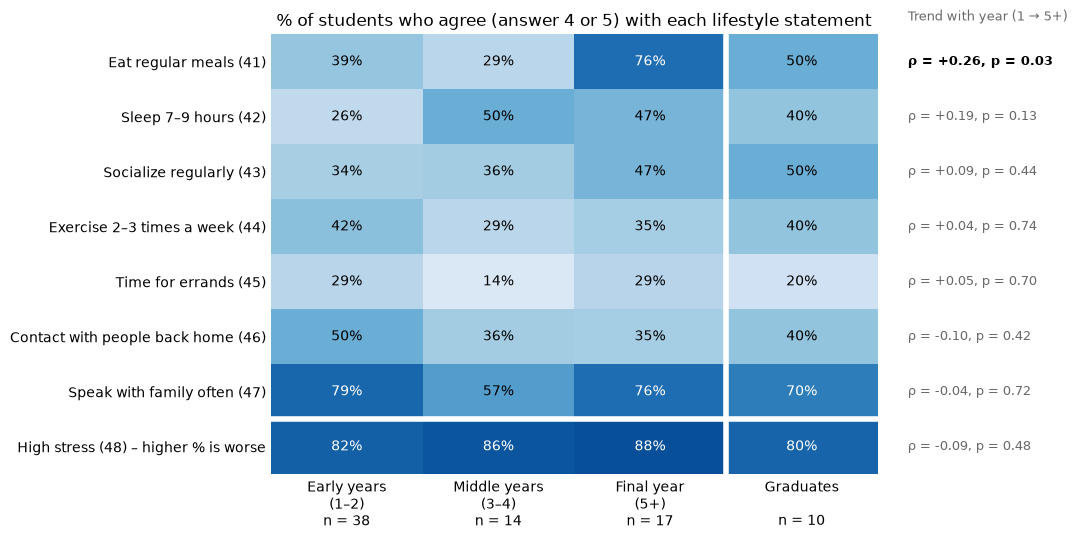

In [38]:
LIFESTYLE = [
    ("41", "Eat regular meals (41)"),
    ("42", "Sleep 7–9 hours (42)"),
    ("43", "Socialize regularly (43)"),
    ("44", "Exercise 2–3 times a week (44)"),
    ("45", "Time for errands (45)"),
    ("46", "Contact with people back home (46)"),
    ("47", "Speak with family often (47)"),
    ("48", "Stress level (48)"),
]
LIFESTYLE_COLS = [col for col, _ in LIFESTYLE]
LIFESTYLE_LABELS = [label for _, label in LIFESTYLE]
# In this chart the stress row counts students with HIGH stress, so a higher % means worse wellbeing
AGREE_LABELS = LIFESTYLE_LABELS[:-1] + ["High stress (48) – higher % is worse"]

# % of each group answering 4 or 5 (agree / strongly agree; for stress: high / very high)
agree = (df[LIFESTYLE_COLS] >= 4).where(df[LIFESTYLE_COLS].notna()).groupby(df["year_group"]).mean().T
agree = agree.reindex(columns=GROUP_ORDER).set_axis(AGREE_LABELS)

# Spearman correlation between year (1-5) and the answer: do answers go up or down in higher years?
trend = pd.DataFrame(
    [stats.spearmanr(students["year_num"], students[col], nan_policy="omit") for col in LIFESTYLE_COLS],
    index=AGREE_LABELS, columns=["Spearman ρ with year", "p-value"])
display((agree * 100).round(0).set_axis([g.replace("\n", " ") for g in GROUP_ORDER], axis=1))
display(trend.round(3))

fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(agree.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for r in range(agree.shape[0]):
    for c in range(agree.shape[1]):
        value = agree.iat[r, c]
        ax.text(c, r, f"{value:.0%}", ha="center", va="center", fontsize=10, color="white" if value > 0.6 else "black")
    rho, p = trend.iloc[r]
    ax.text(3.7, r, f"ρ = {rho:+.2f}, p = {p:.2f}", va="center", fontsize=9,
            color="black" if p < 0.05 else "dimgrey", fontweight="bold" if p < 0.05 else "normal")
ax.text(3.7, -0.75, "Trend with year (1 → 5+)", fontsize=9, color="dimgrey")
ax.axhline(6.5, color="white", linewidth=4)  # stress is set apart: for it, a high % means worse wellbeing
ax.axvline(2.5, color="white", linewidth=4)
ns = df["year_group"].value_counts().reindex(GROUP_ORDER)
ax.set_xticks(range(len(GROUP_ORDER)), [f"{g}\nn = {n}" for g, n in zip(GROUP_ORDER, ns)])
ax.set_yticks(range(len(LIFESTYLE)), AGREE_LABELS)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("% of students who agree (answer 4 or 5) with each lifestyle statement")
plt.tight_layout()
plt.show()

## How students see neurodivergence

**Columns used**
- Column 14, *"To you, neurodivergence is primarily…"*: 4 fixed options plus an *Other* box. 1 student skipped it, so n = 78.
- Split by neurodivergent vs not neurodivergent students (column 9, as in the first chart).

**How the answers were coded**
- **8 students wrote their own answer.** Each one was read: all of them combine several options (e.g. *"all of the above"*, *"a brain difference that also causes challenges"*, *"it depends on the neurodivergence"*). They are grouped as **Mixed / several views** instead of being forced into one option.
- The 5 answers are put in order, from a **deficit / medical view** (top) to a **difference / strengths view** (bottom), with *Mixed* in the middle.

**What the graph shows**
- Each answer has **two bars**: blue = neurodivergent students, orange = not neurodivergent students.
- Bars show the **% of each group** that chose the answer, with the number of students in brackets. Using % instead of counts makes the two groups comparable, because they are not the same size.
- The bold numbers on the right are for **all students together** (n = 78).

**Method: Fisher's exact test**
- For each answer, checks whether one group chooses it more often than the other. It is used instead of a chi-square test because several cells have fewer than 5 students. p < 0.05 = significant.

**Reading the numbers**
- Each p-value comes from a 2 × 2 table, for example for *a unique way of thinking*: 7 of 42 ND students chose it vs 13 of 36 not ND students.
- **p = 0.069** (*a unique way of thinking*, 17% vs 36%): the closest to significant. A difference this large would appear by chance about 7 times in 100. That is above 0.05, so it is **not significant**, but it is a hint worth checking in a larger sample.
- **p = 0.47** (*a challenge in daily life*, 38% vs 28%): a gap like this would appear by chance almost half the time. No evidence of a difference.
- **p = 0.21** (*a disorder needing treatment*, 0 vs 2 students): with only 2 students choosing this answer, no test could show a difference.

**Conclusions**
- **Almost nobody sees neurodivergence as a disorder needing treatment.** Only 2 students (3%) chose *a disorder needing treatment*, and neither of them is neurodivergent.
- **Answers are spread across the other views**: *a challenge in daily life* (26 students, 33%), *a brain difference, not a deficit* (22, 28%) and *a unique way of thinking* (20, 26%).
- **Neurodivergent and non-neurodivergent students answer in much the same way.** Neurodivergent students chose *a unique way of thinking* less often (17% vs 36%, p = 0.07) and *a challenge in daily life* a little more often (38% vs 28%, p = 0.47), but **no difference is significant**.
- Neurodivergent students wrote more *mixed* answers (6 vs 2 students, p = 0.28), often saying that neurodivergence is a difference *and* a challenge at the same time.

**Limits**
- With about 40 students per group, only large differences can be detected. The *unique way of thinking* difference may be real but would need a larger sample to confirm.

,free-text answers coded as 'Mixed / several views'
24,It‘s all of the above. It‘s a challangr becaus...
25,A unique way of thinking that comes both with ...
26,"A combination of all of the above, with a very..."
38,It depends on the neuro divergence. Some need ...
56,All answers are true at the same time
66,All of them except a disorder
71,A brain difference that also causes challenges...
76,All above


,students
view,
A disorder needing treatment,2
A challenge in daily life,26
Mixed / several views,8
"A brain difference, not a deficit",22
A unique way of thinking,20


nd_group,Neurodivergent,Not neurodivergent,all,% of all,p-value ND vs not ND (Fisher)
view,,,,,
A disorder needing treatment,0,2,2,3.0,0.210
A challenge in daily life,16,10,26,33.0,0.470
Mixed / several views,6,2,8,10.0,0.275
"A brain difference, not a deficit",13,9,22,28.0,0.620
A unique way of thinking,7,13,20,26.0,0.069


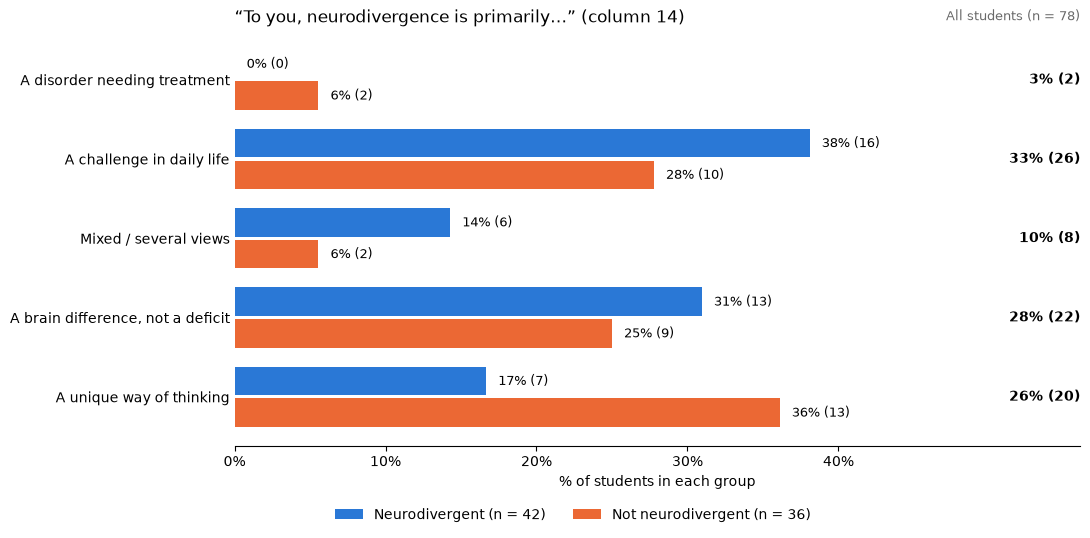

In [39]:
# Column 14 has 4 fixed options plus free-text "Other" answers. Every free-text answer was read and coded by hand:
# all of them combine several of the fixed options ("all of the above", "a difference AND a challenge", "it depends"),
# so they get their own category instead of being forced into one option.
VIEW_ORDER = [
    "A disorder needing treatment",
    "A challenge in daily life",
    "Mixed / several views",
    "A brain difference, not a deficit",
    "A unique way of thinking",
]
# Ordered from a deficit / medical view (left) to a difference / strengths view (right)
VIEW_COLORS = ["#b8302f", "#f0a09f", "#c3c2b7", "#86b6ef", "#1c5cab"]

df["view"] = df["14"].where(df["14"].isin(VIEW_ORDER) | df["14"].isna(), "Mixed / several views")
display(df.loc[df["view"] == "Mixed / several views", "14"].to_frame("free-text answers coded as 'Mixed / several views'"))
display(df["view"].value_counts().reindex(VIEW_ORDER).to_frame("students"))

answered = df.dropna(subset=["view"])
GROUPS = [("Neurodivergent", ND_COLOR), ("Not neurodivergent", NON_ND_COLOR)]
view_counts = pd.crosstab(answered["view"], answered["nd_group"]).reindex(index=VIEW_ORDER, columns=[g for g, _ in GROUPS])
view_share = view_counts / view_counts.sum()
# Fisher's exact test for each answer: is it chosen more often by one group than the other?
view_p = {view: stats.fisher_exact([view_counts.loc[view], view_counts.sum() - view_counts.loc[view]]).pvalue
          for view in VIEW_ORDER}
display(view_counts.assign(all=view_counts.sum(axis=1),
                           **{"% of all": (view_counts.sum(axis=1) / len(answered) * 100).round(0),
                              "p-value ND vs not ND (Fisher)": pd.Series(view_p).round(3)}))

fig, ax = plt.subplots(figsize=(11, 5.5))
bar_h = 0.36
for k, (group, color) in enumerate(GROUPS):
    y = np.arange(len(VIEW_ORDER)) + (k - 0.5) * (bar_h + 0.04)
    n_group = view_counts[group].sum()
    ax.barh(y, view_share[group], height=bar_h, color=color, label=f"{group} (n = {n_group})")
    for yi, share_i, n in zip(y, view_share[group], view_counts[group]):
        ax.text(share_i + 0.008, yi, f"{share_i:.0%} ({n})", va="center", fontsize=9)

# Right-hand column: the whole sample together
totals_all = view_counts.sum(axis=1)
for i, n in enumerate(totals_all):
    ax.text(0.56, i, f"{n / len(answered):.0%} ({n})", va="center", ha="right", fontsize=10, fontweight="bold")
ax.text(0.56, -0.75, f"All students (n = {len(answered)})", ha="right", fontsize=9, color="dimgrey")

ax.set_yticks(range(len(VIEW_ORDER)), VIEW_ORDER)
ax.invert_yaxis()
ax.set_xlim(0, 0.56)
ax.set_xticks([0, 0.1, 0.2, 0.3, 0.4])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("% of students in each group")
ax.set_title("“To you, neurodivergence is primarily…” (column 14)", loc="left")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.4, -0.12), frameon=False)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### Answers by condition (100% stacked bars)

**Columns used**
- Column 14 (coded as above) and column 10, *"Which of the following apply to you?"*.

**How the conditions were grouped**
- Column 10 allowed more than one answer, so **a student who ticked 3 conditions is counted in all 3 rows.** The rows are not separate groups of people and do not add up to 79.
- Conditions ticked by fewer than 5 students (bipolar, SPD, APD, BPD, dyspraxia) are pooled as **Other conditions**. *None* was only ticked once, together with *Not sure*, so that student is counted under *Not sure*.
- *Not sure* and *No condition ticked* (column 10 left empty) are kept as comparison rows.

**What the graph shows**
- Each bar is the students who ticked one condition, and adds up to 100%. The colored parts show how those students answered column 14.
- Red = deficit view, grey = mixed, blue = difference view.
- **n** is the number of students in the row. Rows with n below 10 (dyslexia, PTSD, OCD, other) should be read with care: one student changes the bar by 10–20%.

**Conclusions**
- **No student who ticked a condition sees neurodivergence as "a disorder needing treatment".** The only 2 students who chose it ticked no condition at all.
- **For ADHD, anxiety and depression, answers are split**: 35–41% see it as *a challenge in daily life* and 39–49% as *a brain difference* or *a unique way of thinking*.
- **Students with dyslexia are the most positive**: 8 of 9 see it as a difference or a unique way of thinking.
- **Students with ASD give the most mixed answers** (31% wrote their own mixed answer) and none chose *a unique way of thinking*.

**Limits**
- No statistical test is used: the rows overlap (one student can be in several rows) and most are small, so this chart is descriptive only.

view,A disorder needing treatment,A challenge in daily life,Mixed / several views,"A brain difference, not a deficit",A unique way of thinking,total
condition,,,,,,
ADHD,0,11,5,8,7,31
Anxiety Disorder,0,12,5,7,5,29
Depression Disorder,0,7,4,3,4,18
ASD,0,4,4,5,0,13
Dyslexia,0,1,0,4,4,9
PTSD,0,1,0,4,0,5
OCD,0,2,0,2,1,5
Other conditions,0,1,3,2,1,7
Not sure,0,4,0,4,7,15


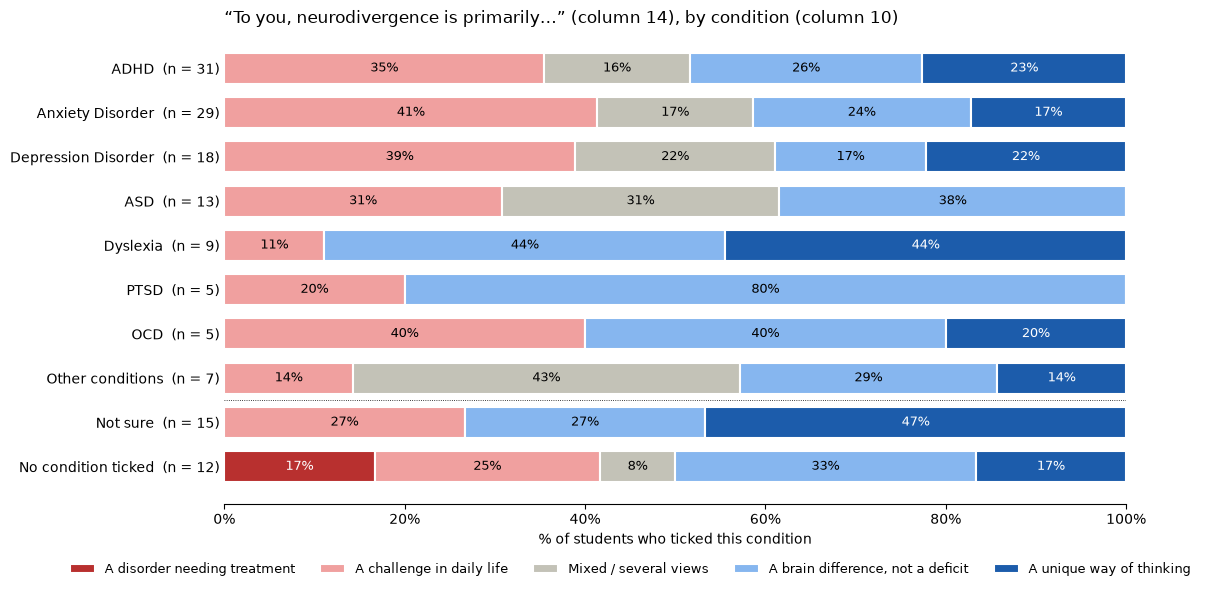

In [40]:
# Column 10 is multi-select: one True/False column per condition. A student who ticked 3 conditions appears in 3 rows.
cond = df["10"].str.get_dummies(sep=";").astype(bool)
cond.columns = cond.columns.str.split(" – ").str[0]
# Conditions with fewer than 5 students are pooled so that no row rests on 1–3 people
SMALL = ["Bipolar Disorder", "Sensory Processing Differences (SPD)", "APD", "BPD", "Dyspraxia / DCD"]
assert (cond[SMALL].sum() < 5).all(), "a pooled condition has 5 or more students"
cond["Other conditions"] = cond[SMALL].any(axis=1)
cond["No condition ticked"] = df["10"].isna()  # left column 10 empty
assert df.loc[cond["None"], "10"].eq("None;Not sure").all(), "'None' should only appear together with 'Not sure'"
cond = cond.drop(columns=SMALL + ["None"])

COND_ORDER = ["ADHD", "Anxiety Disorder", "Depression Disorder", "ASD", "Dyslexia", "PTSD", "OCD",
              "Other conditions", "Not sure", "No condition ticked"]

# Long table: one row per (student, condition they ticked)
long = (cond[COND_ORDER].join(df["view"]).dropna(subset=["view"])
        .melt(id_vars="view", var_name="condition", value_name="ticked")
        .query("ticked").drop(columns="ticked"))
counts = pd.crosstab(long["condition"], long["view"]).reindex(index=COND_ORDER, columns=VIEW_ORDER, fill_value=0)
share = counts.div(counts.sum(axis=1), axis=0)
display(counts.assign(total=counts.sum(axis=1)))

fig, ax = plt.subplots(figsize=(12, 6))
left = np.zeros(len(COND_ORDER))
for view, color in zip(VIEW_ORDER, VIEW_COLORS):
    widths = share[view].values
    ax.barh(range(len(COND_ORDER)), widths, left=left, height=0.7, color=color,
            edgecolor="white", linewidth=1.5, label=view)
    for i, (w, n) in enumerate(zip(widths, counts[view].values)):
        if w >= 0.08:  # label only segments wide enough to hold the text
            ax.text(left[i] + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if color in ("#b8302f", "#1c5cab") else "black")
    left += widths

totals = counts.sum(axis=1)
ax.set_yticks(range(len(COND_ORDER)), [f"{c}  (n = {n})" for c, n in zip(COND_ORDER, totals)])
ax.invert_yaxis()
ax.axhline(7.5, color="black", linewidth=0.6, linestyle=":")  # conditions above, "unsure / none" below
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("% of students who ticked this condition")
ax.set_title("“To you, neurodivergence is primarily…” (column 14), by condition (column 10)", loc="left")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.1), frameon=False, fontsize=9)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

## How neurodivergence is perceived in each environment

### From family to university

**Columns used**
- **Family (16)** and **cultural environment (17)**: 1 = *very stigmatised*, 2 = *mostly dismissed*, 3 = *mixed / neutral*, 4 = *mostly accepted*, 5 = *widely accepted*. 2 students skipped column 17.
- Three university questions answered from 1 (strongly disagree) to 5 (strongly agree):
  - **Classmates (25)**: *"My classmates and peers are accepting and non-judgmental toward neurodivergent students."*
  - **Professors (24)**: *"Professors in your program are flexible and supportive toward neurodivergent students."*
  - **Teaching style (23)**: *"Do you believe the teaching style in your University is accessible for diverse learners?"*
- Two yes / no questions about professors (columns 20 and 21), shown in the tables above the chart.
- Column 28 (fear of revealing neurodivergence to professors) is shown in the next chart, because only neurodivergent students answered it and it measures fear, not acceptance.

**What the graph shows (diverging stacked bars)**
- Each environment has two bars: **neurodivergent** and **not neurodivergent** students (column 9, as in the first chart).
- Negative answers (1–2, red) go **left** of the centre line and positive answers (4–5, blue) go **right**. Neutral answers (3, grey) are split in half across the centre. The further a bar reaches right, the more accepting that environment is seen to be.
- Numbers inside the bars are the % of the group.

**Method**
- **Mann-Whitney U test** (ND vs not ND, for each environment): checks whether one group tends to give higher answers. p < 0.05 = significant.
- **Wilcoxon signed-rank test** (family vs cultural environment): the same students answered both questions, so a *paired* test is used.

**Reading the numbers**
- **Family vs cultural environment: Wilcoxon p = 0.042.** Each student's two answers were compared with each other. More students rated their family higher than their culture than the other way round, and a split this one-sided would appear by chance only about 4 times in 100. Significant, but close to the 0.05 line.
- **Professors vs teaching style: Spearman ρ = 0.60, p < 0.001.** A **strong** link (ρ² ≈ 0.36): students who rate one low tend to rate the other low too.
- **ND vs not ND: Mann-Whitney p = 0.10 to 0.82.** None is below 0.05. The smallest (cultural environment, 2.54 vs 2.94, p = 0.10) would appear by chance about 1 time in 10.

**Conclusions**
- **Students feel accepted by their classmates.** 67% agree their peers are accepting and non-judgmental, and only 6% disagree. Classmates are the most accepting part of the environment.
- **The university's teaching side is seen as the least accessible.** Only 16% agree professors are flexible and supportive (49% disagree), and only 10% find the teaching style accessible for diverse learners (56% disagree). The two answers go together (Spearman ρ = 0.60): students who find professors unsupportive also find the teaching inaccessible.
- **Professors rarely talk about neurodivergence**: only 10% of students believe most professors are aware and accepting of it (48% are not sure), and 84% say it has never been discussed in class.
- **Family is split**: about a third see it as stigmatising or dismissive (33%) and a third as accepting (35%).
- **The cultural environment is seen as less accepting than the family** (average 2.73 vs 3.03, Wilcoxon p = 0.042): 36% describe it as stigmatising or dismissive and only 23% as accepting.
- **Neurodivergent and non-neurodivergent students see their environment in much the same way.** No difference is significant. Neurodivergent students rate their cultural environment a little lower (2.54 vs 2.94, p = 0.10), but this could be chance.

,environment,n,% negative (1–2),% positive (4–5),"average, all","average, ND","average, not ND",p-value ND vs not ND
0,Family (16),79,32.91,35.44,3.03,2.93,3.14,0.41
1,Cultural environment (17),77,36.36,23.38,2.73,2.54,2.94,0.10
2,Classmates are accepting and non-judgmental (25),79,6.33,67.09,3.85,3.79,3.92,0.43
3,Professors are flexible and supportive (24),79,49.37,16.46,2.56,2.52,2.59,0.82
4,Teaching style is accessible for diverse learn...,79,55.70,10.13,2.41,2.36,2.46,0.50


Family vs cultural environment: average 3.03 vs 2.73, Wilcoxon signed-rank p = 0.042
Professors (24) vs teaching style (23): Spearman ρ = 0.60


,students,%
Most professors are aware and accepting of neurodivergence (20),,
Not sure,38,48.0
No,33,42.0
Yes,8,10.0


,students,%
Professors have discussed neurodivergence in class (21),,
No,66,84.0
Shortly,10,13.0
Yes,3,4.0


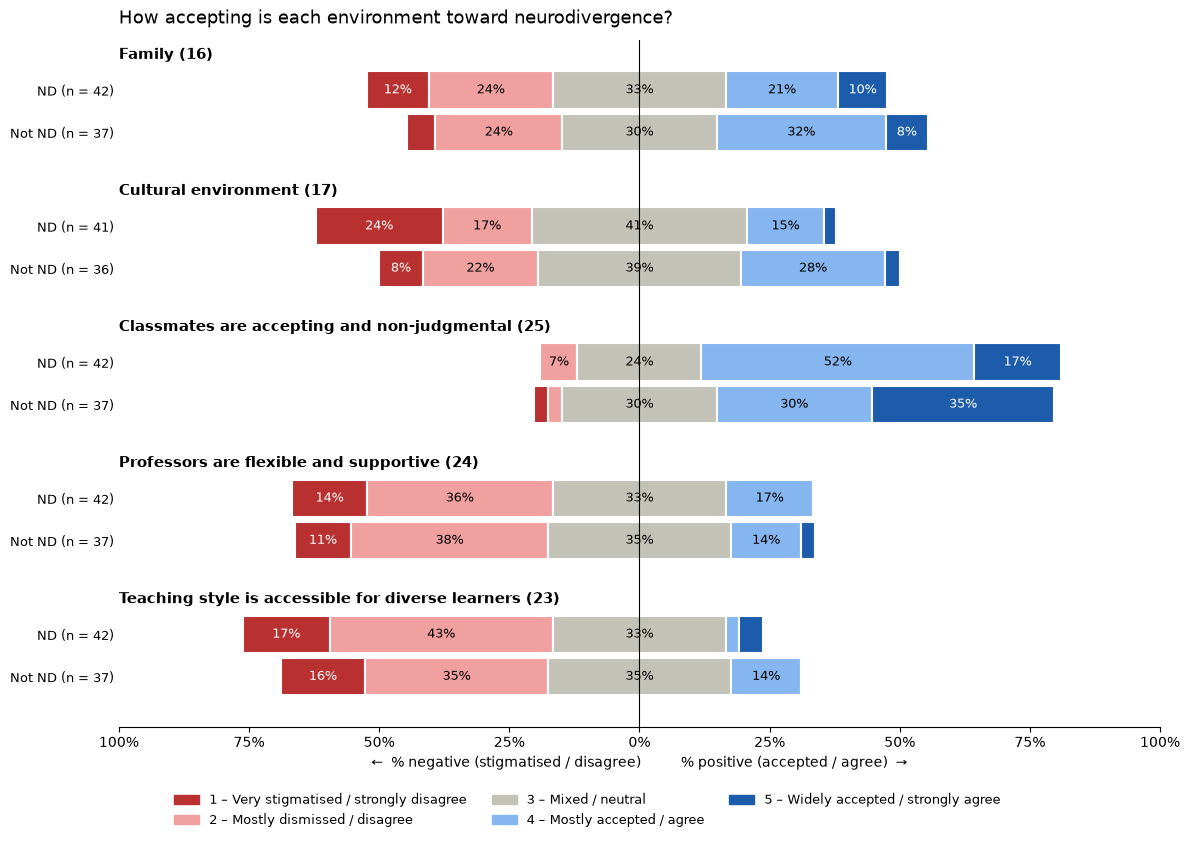

In [41]:
# Ordered from the closest circle (family) out to the university
ENVIRONMENTS = [
    ("16", "Family (16)"),
    ("17", "Cultural environment (17)"),
    ("25", "Classmates are accepting and non-judgmental (25)"),
    ("24", "Professors are flexible and supportive (24)"),
    ("23", "Teaching style is accessible for diverse learners (23)"),
]
LEVEL_LABELS = ["1 – Very stigmatised / strongly disagree", "2 – Mostly dismissed / disagree", "3 – Mixed / neutral",
                "4 – Mostly accepted / agree", "5 – Widely accepted / strongly agree"]
LIKERT_COLORS = VIEW_COLORS  # same red → grey → blue scale as the "how students see neurodivergence" charts
GROUP_NAMES = [("Neurodivergent", "ND"), ("Not neurodivergent", "Not ND")]

rows = []
for col, name in ENVIRONMENTS:
    answers = df[col].dropna()
    nd_answers = df.loc[df["nd_group"] == "Neurodivergent", col].dropna()
    non_answers = df.loc[df["nd_group"] == "Not neurodivergent", col].dropna()
    rows.append({
        "environment": name,
        "n": len(answers),
        "% negative (1–2)": (answers <= 2).mean() * 100,
        "% positive (4–5)": (answers >= 4).mean() * 100,
        "average, all": answers.mean(),
        "average, ND": nd_answers.mean(),
        "average, not ND": non_answers.mean(),
        # Mann-Whitney U test: do ND students tend to answer higher or lower than the others?
        "p-value ND vs not ND": stats.mannwhitneyu(nd_answers, non_answers).pvalue,
    })
display(pd.DataFrame(rows).round(2))

# Family vs cultural environment: the same students answered both, so a paired test is used
wilcoxon = stats.wilcoxon(df["16"], df["17"], nan_policy="omit")
print(f"Family vs cultural environment: average {df['16'].mean():.2f} vs {df['17'].mean():.2f}, "
      f"Wilcoxon signed-rank p = {wilcoxon.pvalue:.3f}")
print(f"Professors (24) vs teaching style (23): Spearman ρ = {df['24'].corr(df['23'], method='spearman'):.2f}")

# Supporting yes / no questions about the university
for col, question in [("20", "Most professors are aware and accepting of neurodivergence (20)"),
                      ("21", "Professors have discussed neurodivergence in class (21)")]:
    share = df[col].value_counts()
    display(pd.DataFrame({"students": share, "%": (share / share.sum() * 100).round(0)}).rename_axis(question))

fig, ax = plt.subplots(figsize=(12, 8.5))
bar_h, pair_gap = 0.8, 2.9
yticks, ylabels = [], []
for i, (col, name) in enumerate(ENVIRONMENTS):
    ax.text(-1.0, i * pair_gap - 0.75, name, fontsize=11, fontweight="bold", va="center")
    for k, (group, short) in enumerate(GROUP_NAMES):
        y = i * pair_gap + k * (bar_h + 0.1)
        answers = df.loc[df["nd_group"] == group, col].dropna()
        shares = answers.value_counts(normalize=True).reindex(range(1, 6), fill_value=0).values
        # Centre the bar on the middle of the neutral answer: 1–2 to the left, 4–5 to the right
        left = -(shares[0] + shares[1] + shares[2] / 2)
        for share, color in zip(shares, LIKERT_COLORS):
            ax.barh(y, share, left=left, height=bar_h, color=color, edgecolor="white", linewidth=1.5)
            if share >= 0.07:  # label only segments wide enough to hold the text
                ax.text(left + share / 2, y, f"{share:.0%}", ha="center", va="center", fontsize=9,
                        color="white" if color in ("#b8302f", "#1c5cab") else "black")
            left += share
        yticks.append(y)
        ylabels.append(f"{short} (n = {len(answers)})")

ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(yticks, ylabels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-1, 1)
ax.set_xticks([-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{abs(x):.0%}"))
ax.set_xlabel("←  % negative (stigmatised / disagree)          % positive (accepted / agree)  →")
ax.set_title("How accepting is each environment toward neurodivergence?", loc="left", fontsize=13, pad=12)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in LIKERT_COLORS], LEVEL_LABELS,
          ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.08), frameon=False, fontsize=9)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### Fear of revealing neurodivergence to professors

**Columns used**
- Column 28, *"How afraid are you of revealing your neurodivergence to professors?"*: 40 of the 42 neurodivergent students answered. The 5 non-neurodivergent students who answered anyway are left out, because the question asked them to skip it.
- **Scale:** 1 = *really afraid*, 5 = *not afraid at all*. A **lower** answer means **more** fear.
- The five environment questions from the previous chart, plus *comfort in the university environment* (49) and *feeling supported as a vet student* (50).

**What the graph shows**
- **Left:** how many neurodivergent students gave each answer. The **shaded area** covers answers of 1 or 2 (afraid or really afraid).
- **Right:** whether fear is linked to how students see their environment. Because a higher answer to column 28 means *less* fear, a **positive** bar means that students who see an environment as more accepting are **less afraid**.

**Method**
- **Mann-Whitney U test**: diagnosed vs self-identified students.
- **Spearman correlation (ρ)**: column 28 vs each environment question, from −1 to +1. p < 0.05 = significant.

**Reading the numbers**
- **Diagnosed vs self-identified: p = 0.92** (3.24 vs 3.33). The two groups are almost identical; a gap this small would appear by chance more than 9 times in 10.
- **Comfort at university: ρ = 0.28, p = 0.078** and **classmates: ρ = 0.26, p = 0.10.** Weak-to-moderate positive links, in the expected direction (more comfortable → less afraid). With 40 students, ρ needs to be about 0.31 to reach p < 0.05, so they fall just short. **Not significant, but they could be real.**
- **Professors: ρ = −0.10, p = 0.55.** Practically no link.

**Conclusions**
- **A quarter of neurodivergent students are afraid to tell their professors, and almost half are not.** 10 of 40 (25%) answered 1 or 2 (afraid), 12 (30%) are in the middle and 18 (45%) answered 4 or 5 (not afraid). The average is 3.3, slightly on the *not afraid* side.
- **There is no sign that diagnosed and self-identified students differ** (average 3.2 vs 3.3, p = 0.92). Having an official diagnosis does not seem to make students feel safer to disclose.
- **Students who feel more comfortable at university and more accepted by classmates tend to be less afraid** (comfort ρ = 0.28, p = 0.08; classmates ρ = 0.26, p = 0.10), but **none of the links is significant**, so they could be chance.
- **How students see their professors is not linked to fear** (ρ = −0.10, p = 0.55). Even though few students find professors supportive (previous chart), this does not seem to decide whether a student is afraid to disclose.

**Limits**
- With 40 students, a correlation has to be about ρ = 0.31 to reach p < 0.05, and about 0.43 to be detected reliably. Weaker links, like the ones for comfort and classmates, may be real but cannot be shown with this sample.

Fear of revealing ND to professors: n = 40, average = 3.27, afraid (1–2): 10 (25%), not afraid (4–5): 18 (45%)


,count,mean
diagnosis,,
Diagnosed,25,3.24
Self-identified only,15,3.33


Diagnosed vs self-identified only: Mann-Whitney p = 0.92


,Spearman ρ with column 28,p-value
Family (16),0.097,0.554
Cultural environment (17),0.201,0.219
Classmates accepting (25),0.263,0.101
Professors flexible and supportive (24),-0.097,0.550
Teaching style accessible (23),0.095,0.558
Comfort in university environment (49),0.282,0.078
Feeling supported as a vet student (50),0.226,0.161


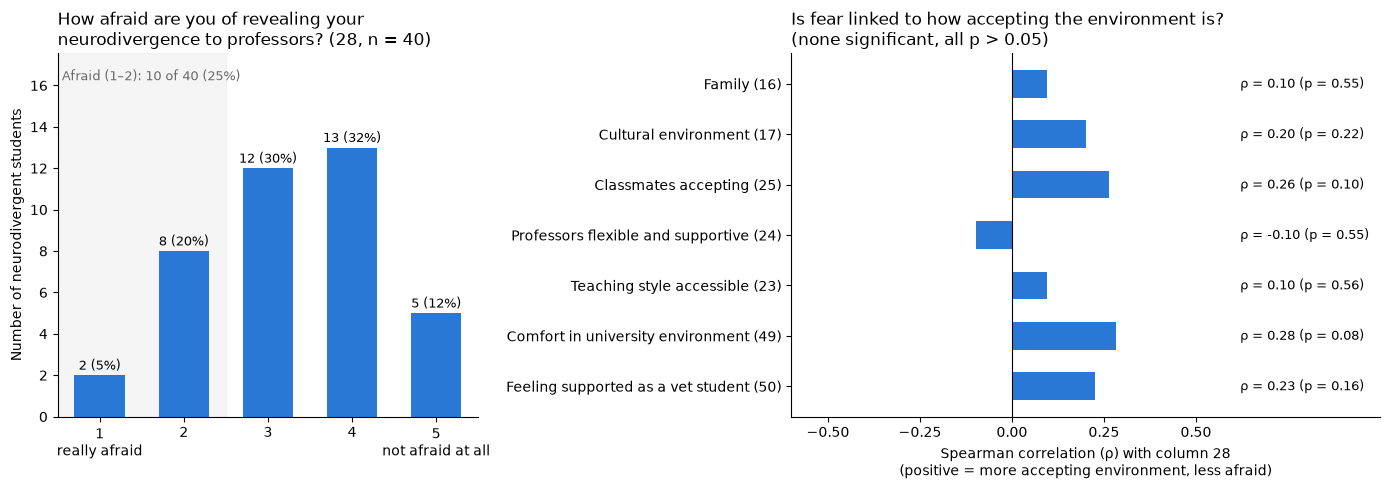

In [ ]:
FEAR_LINKS = [
    ("Family (16)", "16"),
    ("Cultural environment (17)", "17"),
    ("Classmates accepting (25)", "25"),
    ("Professors flexible and supportive (24)", "24"),
    ("Teaching style accessible (23)", "23"),
    ("Comfort in university environment (49)", "49"),
    ("Feeling supported as a vet student (50)", "50"),
]

# Column 28 asked non-ND students to skip it, so only neurodivergent students are used
# Scale: 1 = really afraid, 5 = not afraid at all (a LOWER answer means MORE fear)
nd_students = df[df["neurodivergent"]].copy()
nd_students["diagnosis"] = nd["diagnosis"]  # diagnosed vs self-identified only, from the earlier chart
fear = nd_students["28"].dropna()
n = len(fear)
afraid, not_afraid = (fear <= 2).sum(), (fear >= 4).sum()
print(f"Fear of revealing ND to professors: n = {n}, average = {fear.mean():.2f}, "
      f"afraid (1–2): {afraid} ({afraid / n:.0%}), not afraid (4–5): {not_afraid} ({not_afraid / n:.0%})")

# Diagnosed vs self-identified: does an official diagnosis change the fear?
by_diag = nd_students.groupby("diagnosis")["28"].agg(["count", "mean"])
mw = stats.mannwhitneyu(nd_students.loc[nd_students["diagnosis"] == "Diagnosed", "28"].dropna(),
                        nd_students.loc[nd_students["diagnosis"] == "Self-identified only", "28"].dropna())
display(by_diag.round(2))
print(f"Diagnosed vs self-identified only: Mann-Whitney p = {mw.pvalue:.2f}")

# Spearman correlation between column 28 and each perception of the environment.
# Positive ρ = students who see the environment as more accepting are LESS afraid
fear_corr = pd.DataFrame(
    [stats.spearmanr(nd_students["28"], nd_students[col], nan_policy="omit") for _, col in FEAR_LINKS],
    index=[name for name, _ in FEAR_LINKS], columns=["Spearman ρ with column 28", "p-value"])
display(fear_corr.round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.4]})

# Left: distribution of fear
counts = fear.value_counts().reindex(range(1, 6), fill_value=0)
ax1.axvspan(0.5, 2.5, color="grey", alpha=0.08)
ax1.text(0.55, counts.max() * 1.25, f"Afraid (1–2): {afraid} of {n} ({afraid / n:.0%})",
         fontsize=9, color="dimgrey", ha="left")
bars = ax1.bar(counts.index, counts.values, width=0.6, color=ND_COLOR)
for bar, c in zip(bars, counts.values):
    ax1.annotate(f"{c} ({c / n:.0%})", (bar.get_x() + bar.get_width() / 2, c),
                 xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
ax1.set_xticks(range(1, 6), ["1\nreally afraid", "2", "3", "4", "5\nnot afraid at all"])
ax1.set_xlim(0.5, 5.5)
ax1.set_ylim(0, counts.max() * 1.35)
ax1.set_ylabel("Number of neurodivergent students")
ax1.set_title(f"How afraid are you of revealing your\nneurodivergence to professors? (28, n = {n})", loc="left")
ax1.spines[["top", "right"]].set_visible(False)

# Right: is fear linked to how accepting the environment is?
y = range(len(FEAR_LINKS))
ax2.barh(list(y), fear_corr["Spearman ρ with column 28"], height=0.55, color=ND_COLOR)
for i, (rho, p) in enumerate(zip(fear_corr["Spearman ρ with column 28"], fear_corr["p-value"])):
    ax2.text(0.62, i, f"ρ = {rho:.2f} (p = {p:.2f})", va="center", fontsize=9)
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_yticks(list(y), fear_corr.index)
ax2.invert_yaxis()
ax2.set_xlim(-0.6, 1.0)
ax2.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
ax2.set_xlabel("Spearman correlation (ρ) with column 28\n(positive = more accepting environment, less afraid)")
ax2.set_title("Is fear linked to how accepting the environment is?\n(none significant, all p > 0.05)", loc="left")
ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Biggest challenges for neurodivergent students

**Columns used**
- Columns 29–40 list 12 challenges. Each answer is **Really / Somewhat / Least challenging**.
- The question asked non-neurodivergent students to skip it, so only the **42 neurodivergent students** are used (the 9 non-ND students who answered anyway are left out, as with column 28).
- A challenge a student left blank is shown as **Not rated** (grey), so every bar is out of the same 42 students.

**Data check: students answered this question in two different ways**
- The codebook wording asks students to *"select your top 3 challenges … then rank them from 1 to 3"*, but the answers are a rating of each challenge.
- **26 students rated all 12 challenges**, while **14 rated exactly 6** (11 of them two per level, as if picking a few each) and 2 rated 9 or 11. For the 14, a blank probably means "not one of my main challenges", not "no answer".
- To check that this does not change the result, the table above the chart repeats the *really challenging* % using only the 26 students who rated all 12.

**What the graph shows (100% stacked bars)**
- One bar per challenge, sorted from the **biggest challenge** (most students rating it *really challenging*) to the smallest.
- Dark red = really challenging, light red = somewhat, pale = least challenging, grey = not rated.

**Reading the numbers**
- **Agreement of the two orders: Spearman ρ = 0.85, p < 0.001.** The 12 challenges were ranked by *% really challenging* twice: once using all 42 ND students, once using only the 26 who rated all 12. ρ = 0.85 means the two rankings are almost the same, so the answering style does not change which challenges are the biggest.

**Conclusions**
- **The biggest challenge is the study load**: 57% of neurodivergent students find being *overwhelmed by the volume of information* really challenging, and 79% rate it really or somewhat challenging.
- **Next come concentration in long lectures (48%), feeling more anxious or burned out than peers (48%) and having to work harder than others for the same result (43%).** The top challenges are about the academic workload and its emotional cost, more than about social life.
- **The ranking holds for the students who rated all 12**: the same four challenges are at the top (69%, 65%, 54% and 50%) and the two orders agree closely (Spearman ρ = 0.85).
- **Social and support challenges are lower**: feeling misunderstood by peers (26%), communicating with professors (29%) and sensory overload (26%).
- **Accessing university support services is the smallest challenge (12%)** and the one most often left unrated (33%). This may mean students do not use these services at all rather than finding them easy.

**Limits**
- Because of the two answering styles, the exact percentages depend on how blanks are treated. The order of the challenges is more reliable than the exact values.

Neurodivergent students: 42. Challenges rated per student:


,students
12,26
11,1
9,1
6,14


,Really challenging,Somewhat challenging,Least challenging,Not rated,% really
Overwhelmed by the volume of information to study,24,9,6,3,57.0
Difficulty concentrating during long lectures or practicals,20,12,5,5,48.0
Feeling more anxious or burned out than peers,20,9,7,6,48.0
Having to work harder than others for the same result,18,12,7,5,43.0
Retaining or recalling information during exams,15,14,10,3,36.0
Masking or hiding difficulties to appear “normal”,15,11,10,6,36.0
Managing deadlines and organising workload,14,15,5,8,33.0
Reading or processing large amounts of written material,14,14,8,6,33.0
Communicating with professors or asking for help,12,5,13,12,29.0
Sensory overload in busy or loud environments,11,12,7,12,26.0


,"% really, all ND","% really, rated all 12 (n = 26)"
Overwhelmed by the volume of information to study,57.0,69.0
Difficulty concentrating during long lectures or practicals,48.0,65.0
Feeling more anxious or burned out than peers,48.0,54.0
Having to work harder than others for the same result,43.0,50.0
Retaining or recalling information during exams,36.0,27.0
Masking or hiding difficulties to appear “normal”,36.0,42.0
Managing deadlines and organising workload,33.0,38.0
Reading or processing large amounts of written material,33.0,38.0
Communicating with professors or asking for help,29.0,38.0
Sensory overload in busy or loud environments,26.0,38.0


Agreement of the two orders: Spearman ρ = 0.85, p = 0.0005


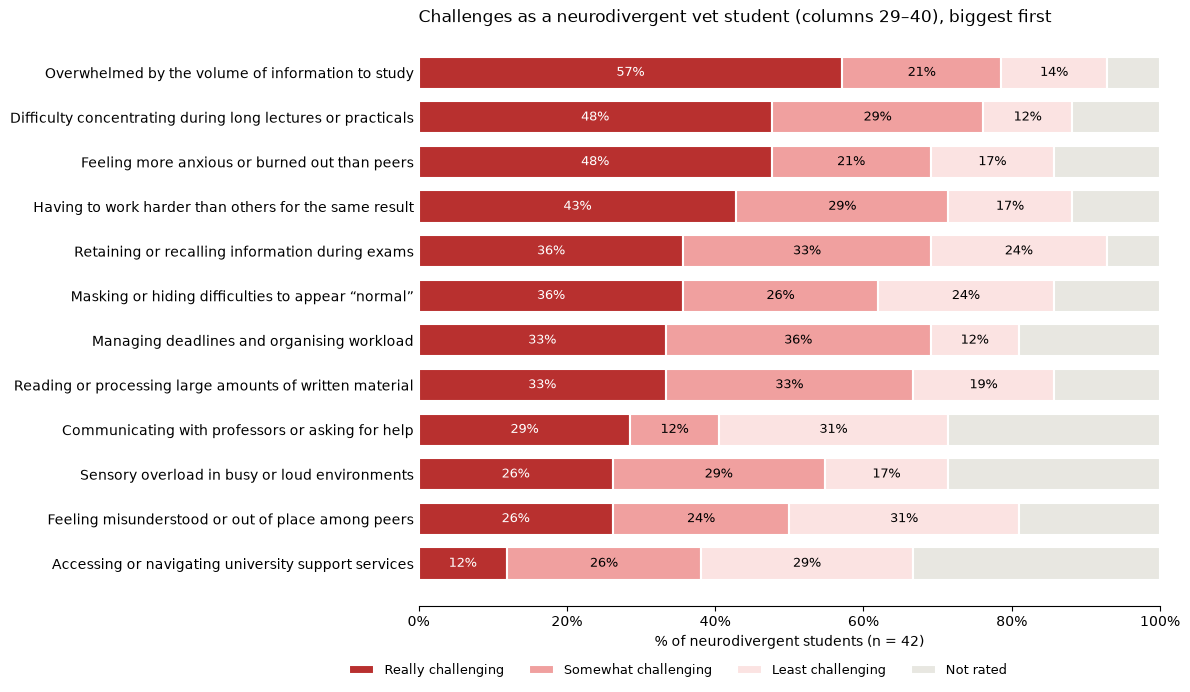

In [ ]:
CHALLENGES = {
    "29": "Difficulty concentrating during long lectures or practicals",
    "30": "Overwhelmed by the volume of information to study",
    "31": "Managing deadlines and organising workload",
    "32": "Sensory overload in busy or loud environments",
    "33": "Reading or processing large amounts of written material",
    "34": "Feeling more anxious or burned out than peers",
    "35": "Retaining or recalling information during exams",
    "36": "Communicating with professors or asking for help",
    "37": "Feeling misunderstood or out of place among peers",
    "38": "Accessing or navigating university support services",
    "39": "Masking or hiding difficulties to appear “normal”",
    "40": "Having to work harder than others for the same result",
}
LEVELS = ["Really challenging", "Somewhat challenging", "Least challenging", "Not rated"]
LEVEL_COLORS = ["#b8302f", "#f0a09f", "#fbe3e2", "#e8e7e1"]  # red ramp (same red as earlier charts) + grey for "not rated"

# Questions 29–40 asked non-ND students to skip them, so only the 42 neurodivergent students are used.
# Every ND student rated at least some challenges, so a challenge left blank = "not rated".
ch = nd_students[list(CHALLENGES)].rename(columns=CHALLENGES).fillna("Not rated")
n_nd = len(ch)
print(f"Neurodivergent students: {n_nd}. Challenges rated per student:")
display(nd_students[list(CHALLENGES)].notna().sum(axis=1).value_counts().sort_index(ascending=False).to_frame("students"))

ch_counts = ch.apply(lambda s: s.value_counts()).reindex(LEVELS).fillna(0).astype(int).T
ch_share = ch_counts / n_nd
# Biggest challenge first: most "really challenging", ties broken by "somewhat"
order = ch_share.sort_values(["Really challenging", "Somewhat challenging"], ascending=False).index
ch_counts, ch_share = ch_counts.loc[order], ch_share.loc[order]
display(ch_counts.assign(**{"% really": (ch_share["Really challenging"] * 100).round(0)}))

# The codebook asks students to pick and rank their top 3, but the answers are a rating of every challenge.
# Most ND students rated all 12, but 14 rated exactly 6 (11 of them two per level), so a blank does not always
# mean the same thing. Check that the order of the challenges is the same when only full raters are used.
full = nd_students[list(CHALLENGES)].notna().all(axis=1)
really_full = (ch[full.values] == "Really challenging").mean().loc[order]
display(pd.DataFrame({"% really, all ND": ch_share["Really challenging"] * 100,
                      f"% really, rated all 12 (n = {full.sum()})": really_full * 100}).round(0))
order_rho, order_p = stats.spearmanr(ch_share["Really challenging"], really_full)
print(f"Agreement of the two orders: Spearman ρ = {order_rho:.2f}, p = {order_p:.4f}")

fig, ax = plt.subplots(figsize=(12, 7))
left = np.zeros(len(order))
for level, color in zip(LEVELS, LEVEL_COLORS):
    widths = ch_share[level].values
    ax.barh(range(len(order)), widths, left=left, height=0.72, color=color,
            edgecolor="white", linewidth=1.5, label=level)
    for i, w in enumerate(widths):
        if w >= 0.06 and level != "Not rated":
            ax.text(left[i] + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if level == "Really challenging" else "black")
    left += widths
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel(f"% of neurodivergent students (n = {n_nd})")
ax.set_title("Challenges as a neurodivergent vet student (columns 29–40), biggest first", loc="left")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.35, -0.08), frameon=False, fontsize=9)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### Challenges by condition

**Columns used**
- Columns 29–40 (challenges, as in the previous chart) and column 10 (conditions), neurodivergent students only.
- Only conditions with **at least 10 neurodivergent students** are shown (ADHD, anxiety, ASD, depression). The others (OCD, dyslexia, PTSD, APD, …) have 1–5 students, too few to compare. Students can have several conditions, so the columns overlap.

**What the graph shows (heatmap)**
- Each cell is the **% of students with that condition who rated the challenge *really challenging***. Darker red = more students.
- The **All ND** column on the left is the reference for all 42 neurodivergent students. Rows are in the same order as the previous chart.
- **\*** = significant difference (see method).

**Method: Fisher's exact test**
- For each cell, compares students with the condition vs the neurodivergent students without it. p < 0.05 = significant. 48 tests are run without correction, so 2–3 "significant" results could appear by chance: read them as hints, not proof.

**Reading the numbers**
- **Each \* compares two groups of ND students**, for example for ADHD and *having to work harder*: 15 of 27 students with ADHD rated it really challenging vs 3 of 15 without ADHD (p = 0.049).
- **4 of the 48 tests are significant** (p = 0.020 to 0.049). By chance alone, about 48 × 0.05 ≈ 2.4 would be expected. So the stars are a little more than chance, but each one on its own could be a false alarm.
- With a Bonferroni correction for 48 tests, the threshold would be 0.05 / 48 ≈ 0.001, and **none would remain significant**. This is why the stars are described as hints.

**Conclusions**
- **Being overwhelmed by the study volume is a top challenge for every condition** (46–65%).
- **ADHD**: concentrating in long lectures (56%) and *having to work harder than others* (56%\*, vs 43% overall) stand out, which fits attention difficulties.
- **Anxiety**: burnout (65%) and **masking** (55%\*) are higher, while *managing deadlines* is much lower (15%\*).
- **Depression**: **masking is the highest value in the chart (70%\*)**, together with work harder (60%) and concentration (60%).
- **ASD**: burnout (62%) and *feeling misunderstood or out of place among peers* (46%, vs 26% overall, p = 0.07) are higher, while concentration is lower (31%). Social difficulties matter more for this group.

**Limits**
- With 10–27 students per condition, one student changes a cell by 4–10%, so only large differences can be detected.
- Blanks count as "not really challenging". For the students who only rated 6 challenges (previous chart) this may slightly lower some cells.

,ND students
ADHD,27
Anxiety,20
ASD,13
Depression,10
Not sure,5
OCD,4
APD,3
Dyslexia,3
PTSD,3
Bipolar,2


,All ND,ADHD,Anxiety,ASD,Depression
Overwhelmed by the volume of information to study,57.0,59.0,65.0,46.0,60.0
Difficulty concentrating during long lectures or practicals,48.0,56.0,45.0,31.0,60.0
Feeling more anxious or burned out than peers,48.0,41.0,65.0,62.0,50.0
Having to work harder than others for the same result,43.0,56.0,40.0,46.0,60.0
Retaining or recalling information during exams,36.0,44.0,25.0,38.0,50.0
Masking or hiding difficulties to appear “normal”,36.0,30.0,55.0,46.0,70.0
Managing deadlines and organising workload,33.0,41.0,15.0,38.0,20.0
Reading or processing large amounts of written material,33.0,41.0,30.0,31.0,50.0
Communicating with professors or asking for help,29.0,26.0,20.0,38.0,20.0
Sensory overload in busy or loud environments,26.0,22.0,35.0,31.0,20.0


,ADHD,Anxiety,ASD,Depression
Overwhelmed by the volume of information to study,0.754,0.366,0.501,1.000
Difficulty concentrating during long lectures or practicals,0.209,0.767,0.190,0.477
Feeling more anxious or burned out than peers,0.336,0.062,0.320,1.000
Having to work harder than others for the same result,0.049,0.764,1.000,0.281
Retaining or recalling information during exams,0.180,0.209,1.000,0.451
Masking or hiding difficulties to appear “normal”,0.325,0.023,0.488,0.020
Managing deadlines and organising workload,0.306,0.023,0.729,0.451
Reading or processing large amounts of written material,0.306,0.750,1.000,0.259
Communicating with professors or asking for help,0.726,0.315,0.463,0.696
Sensory overload in busy or loud environments,0.481,0.298,0.713,1.000


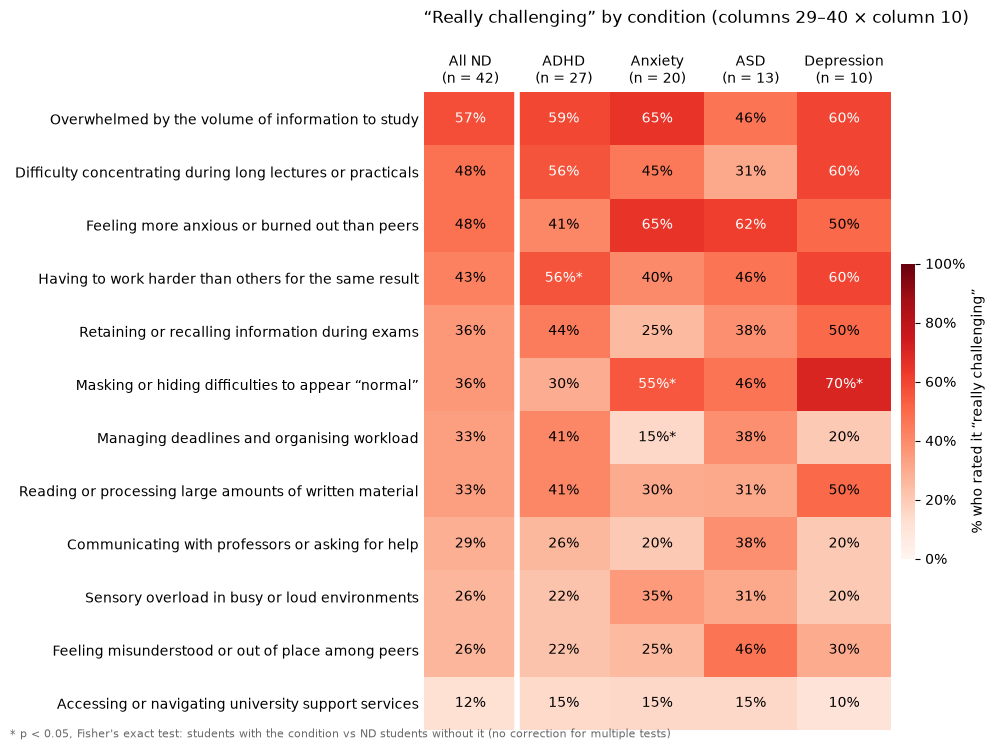

In [ ]:
# Conditions from column 10 with at least 10 ND students; smaller groups (n ≤ 5) are too small to compare
nd_conditions = nd_students["10"].str.get_dummies(sep=";")
nd_conditions.columns = nd_conditions.columns.str.split(" – ").str[0].str.replace(" Disorder", "")  # "Anxiety Disorder" -> "Anxiety"
COND_MIN_N = 10
cond_cols = nd_conditions.sum()[lambda s: s >= COND_MIN_N].sort_values(ascending=False).index.tolist()
display(nd_conditions.sum().sort_values(ascending=False).to_frame("ND students"))

really = ch == "Really challenging"
heat = pd.DataFrame({"All ND": really.mean()})
pvals = pd.DataFrame(index=order, columns=cond_cols, dtype=float)
for cond in cond_cols:
    has = nd_conditions[cond] == 1
    heat[cond] = really[has].mean()
    # Fisher's exact test: students WITH the condition vs ND students WITHOUT it
    for c in order:
        table = [[really.loc[has, c].sum(), (~really.loc[has, c]).sum()],
                 [really.loc[~has, c].sum(), (~really.loc[~has, c]).sum()]]
        pvals.loc[c, cond] = stats.fisher_exact(table).pvalue
heat = heat.loc[order]
cond_n = {"All ND": n_nd, **nd_conditions[cond_cols].sum().to_dict()}
display((heat * 100).round(0))
display(pvals.round(3))

fig, ax = plt.subplots(figsize=(10, 7.5))
im = ax.imshow(heat.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
for i in range(heat.shape[0]):
    for j, col in enumerate(heat.columns):
        v = heat.iloc[i, j]
        star = "*" if col in pvals.columns and pvals.iloc[i, pvals.columns.get_loc(col)] < 0.05 else ""
        ax.text(j, i, f"{v:.0%}{star}", ha="center", va="center", fontsize=10,
                color="white" if v >= 0.55 else "black")
ax.axvline(0.5, color="white", linewidth=4)  # separate the "All ND" reference column
ax.set_xticks(range(heat.shape[1]), [f"{c}\n(n = {cond_n[c]})" for c in heat.columns])
ax.xaxis.tick_top()
ax.set_yticks(range(len(order)), order)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
cbar.set_label("% who rated it “really challenging”")
cbar.outline.set_visible(False)
ax.set_title("“Really challenging” by condition (columns 29–40 × column 10)", loc="left", pad=50)
fig.text(0.01, 0.01, "* p < 0.05, Fisher's exact test: students with the condition vs ND students without it (no correction for multiple tests)",
         fontsize=8, color="dimgrey")
plt.tight_layout()
plt.show()

## Does neurodivergence give strengths?

**Columns used**
- **52**: *"Do you feel your neurodivergence gives you strengths as a student?"* (Yes / No)
- **53**: *"Do you think your neurodivergence will give you strengths as a Veterinary Professional?"* (Yes / No)
- Both questions asked non-neurodivergent students to skip them, so only the **41 neurodivergent students who answered both** are used.

**What the graph shows**
- **Left:** the % of students answering Yes (blue) or No (grey) to each question.
- **Right:** how each student answered the two questions together.

**Method: McNemar exact test**
- The same students answered both questions, so a *paired* test is used. It checks whether students switch from No to Yes more often than from Yes to No. p < 0.05 = significant.

**Reading the numbers**
- **McNemar p = 0.008.** The 33 students who gave the same answer to both questions (18 yes-yes, 15 no-no) are set aside. Of the 8 students who changed their answer, **all 8 went from No to Yes** and none went the other way.
- If neither question got more "yes" answers, each change would be a 50/50 coin flip. Getting 8 out of 8 in the same direction has probability 2 × 0.5⁸ ≈ 0.008 (the 2 counts both directions, because the test is two-sided). That is less than 1 in 100, so it is significant.

**Conclusions**
- **Fewer than half of neurodivergent students feel their neurodivergence is a strength at university (44%), but almost two thirds expect it to be a strength as a vet (63%).**
- **No student went the other way.** All 18 who see a strength now also expect one as a vet. 8 students (20%) see no strength now but expect one in their future job (p = 0.008, significant).
- **Over a third (37%) see no strength in either context.**
- One possible explanation, consistent with the challenges chart: university (study volume, long lectures) is where these students struggle most, while practical work as a vet is imagined as a better fit for the way they think.

**Limits**
- Most students have not worked as a vet yet, so column 53 is an expectation, not an experience.

As a vet (53),Yes,No
As a student (52),,
Yes,18,0
No,8,15


n = 41. Yes as a student: 44%, yes as a future vet: 63%. No → Yes: 8, Yes → No: 0, McNemar exact p = 0.008


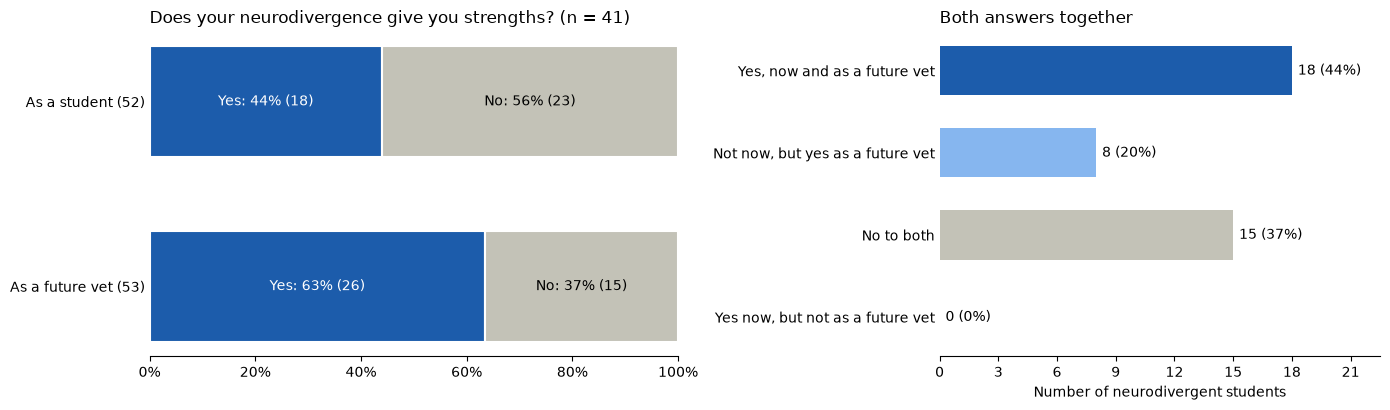

In [ ]:
YES_COLOR, NO_COLOR = "#1c5cab", "#c3c2b7"  # blue / grey from the same scale as the earlier charts

# Columns 52 and 53 asked non-ND students to skip them, so only neurodivergent students who answered both are used
strengths = nd_students[["52", "53"]].dropna()
n_str = len(strengths)
yes_share = (strengths == "Yes").mean()
combo = pd.crosstab(strengths["52"], strengths["53"]).reindex(index=["Yes", "No"], columns=["Yes", "No"], fill_value=0)
display(combo.rename_axis(index="As a student (52)", columns="As a vet (53)"))

# McNemar exact test: the same students answered both, so check if "Yes" is more common for the future than for now
changed_to_yes, changed_to_no = combo.loc["No", "Yes"], combo.loc["Yes", "No"]
mcnemar_p = stats.binomtest(changed_to_yes, changed_to_yes + changed_to_no).pvalue
print(f"n = {n_str}. Yes as a student: {yes_share['52']:.0%}, yes as a future vet: {yes_share['53']:.0%}. "
      f"No → Yes: {changed_to_yes}, Yes → No: {changed_to_no}, McNemar exact p = {mcnemar_p:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})

# Left: % yes / no for each question
QUESTIONS = [("52", "As a student (52)"), ("53", "As a future vet (53)")]
for i, (col, label) in enumerate(QUESTIONS):
    counts = strengths[col].value_counts().reindex(["Yes", "No"], fill_value=0)
    left = 0
    for answer, color in [("Yes", YES_COLOR), ("No", NO_COLOR)]:
        w = counts[answer] / n_str
        ax1.barh(i, w, left=left, height=0.6, color=color, edgecolor="white", linewidth=1.5,
                 label=answer if i == 0 else None)
        ax1.text(left + w / 2, i, f"{answer}: {w:.0%} ({counts[answer]})", ha="center", va="center",
                 fontsize=10, color="white" if answer == "Yes" else "black")
        left += w
ax1.set_yticks(range(len(QUESTIONS)), [label for _, label in QUESTIONS])
ax1.invert_yaxis()
ax1.set_xlim(0, 1)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax1.set_title(f"Does your neurodivergence give you strengths? (n = {n_str})", loc="left")
ax1.spines[["top", "right", "left"]].set_visible(False)
ax1.tick_params(axis="y", length=0)

# Right: how each student answered the two questions together
COMBOS = [("Yes", "Yes", "Yes, now and as a future vet", YES_COLOR),
          ("No", "Yes", "Not now, but yes as a future vet", "#86b6ef"),
          ("No", "No", "No to both", NO_COLOR),
          ("Yes", "No", "Yes now, but not as a future vet", "#f0a09f")]
values = [combo.loc[a, b] for a, b, _, _ in COMBOS]
ax2.barh(range(len(COMBOS)), values, height=0.6, color=[c for *_, c in COMBOS])
for i, v in enumerate(values):
    ax2.text(v + 0.3, i, f"{v} ({v / n_str:.0%})", va="center", fontsize=10)
ax2.set_yticks(range(len(COMBOS)), [label for _, _, label, _ in COMBOS])
ax2.invert_yaxis()
ax2.set_xlim(0, max(values) * 1.25)
ax2.set_xlabel("Number of neurodivergent students")
ax2.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax2.set_title("Both answers together", loc="left")
ax2.spines[["top", "right", "left"]].set_visible(False)
ax2.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

### Strengths by theme and context

**Columns used**
- Column 54 (open question): the 24 neurodivergent students who described their strengths. Non-ND students were asked to skip it.

**How the answers were categorised**
- **Every answer was read by hand** and given two kinds of category: the **strength themes** it describes and the **context** where the strength helps. The categories are written in the code cell below, one line per answer.
- **Strength themes were not fixed in advance.** After reading all the answers, similar strengths were grouped under one name. For example *"hyperfocus"*, *"special interest"* and *"more passion for what I love"* all became **Hyperfocus & passion for interests**. This gave 9 themes:
  - Hyperfocus & passion for interests
  - Pattern recognition & problem solving
  - Empathy & understanding others
  - Attention to detail & observation
  - Creative, out-of-the-box thinking
  - Learning & memory
  - Energy & working under pressure
  - Organisation & reliability
  - Adaptability & resilience
- **One answer can name several strengths**, so it can have more than one theme: 12 answers have one theme, 11 have two and 1 has three. That is why the 24 answers give **37 mentions**, and why the theme counts add up to more than 24.
- **Each answer has only one context**:
  - **Studying**: learning, exams or university tasks (5 answers).
  - **Vet practice**: clinical work, clients, animals or diagnosis (6 answers).
  - **Both**: the answer names a study context and a vet-practice context (5 answers).
  - **General**: no specific context is given (8 answers).
- **Checks in the code**: every ND answer to column 54 must have categories, and each line of categories must match the first words of its answer, so a category cannot end up on the wrong row.

**What the graph shows (visual table)**
- One row per strength theme, most mentioned first.
- **Mentions, by context**: a small bar with the number of answers that named this strength, split by the context where it helps (blue = studying, green = both, orange = vet practice, yellow = general). The length is the count, so the rows can be compared.
- **Example**: one short quote per theme, in the student's own words (spelling as written), with the row of the answer and the context where it helps. The quotes were chosen to be **typical** of the theme. The code checks that each quote is copied word for word from that row and that the row is categorised with that theme.

**Conclusions**
- **The most named strength is hyperfocus and passion for special interests (8 answers)**, followed by **pattern recognition / problem solving**, **empathy and understanding others** and **attention to detail** (5 each).
- **Different strengths help in different places.** Learning & memory and organisation are linked to **studying**. Pattern recognition, empathy and energy for long shifts are linked to **vet practice** (diagnosis, clients and animals). Attention to detail is the strength most often linked to **both**.
- **A third of the answers (8 of 24) name no specific context**, mostly for hyperfocus and creative thinking, which students describe as part of the way they think in general.
- **Only 5 answers link a strength only to studying, while 11 link it to vet practice (6) or to both (5).** This fits columns 52 and 53: students expect their neurodivergence to help more in their future job than at university.
- Strengths about **thinking** (hyperfocus, pattern recognition, creative thinking) and about **people** (empathy) are named much more often than strengths about **organisation** (2) or **adaptability** (1). This fits the challenges chart, where managing workload and deadlines was a common difficulty.

**Limits**
- Most themes have 1–5 mentions, so the order of the smaller themes could easily change with a few more answers.

context,Studying,Both,Vet practice,General,total
theme,,,,,
Hyperfocus & passion for interests,3,1,0,4,8
Pattern recognition & problem solving,0,1,3,1,5
Empathy & understanding others,0,1,2,2,5
Attention to detail & observation,1,3,1,0,5
"Creative, out-of-the-box thinking",0,0,1,3,4
Learning & memory,3,1,0,0,4
Energy & working under pressure,0,0,2,1,3
Organisation & reliability,2,0,0,0,2
Adaptability & resilience,0,0,0,1,1


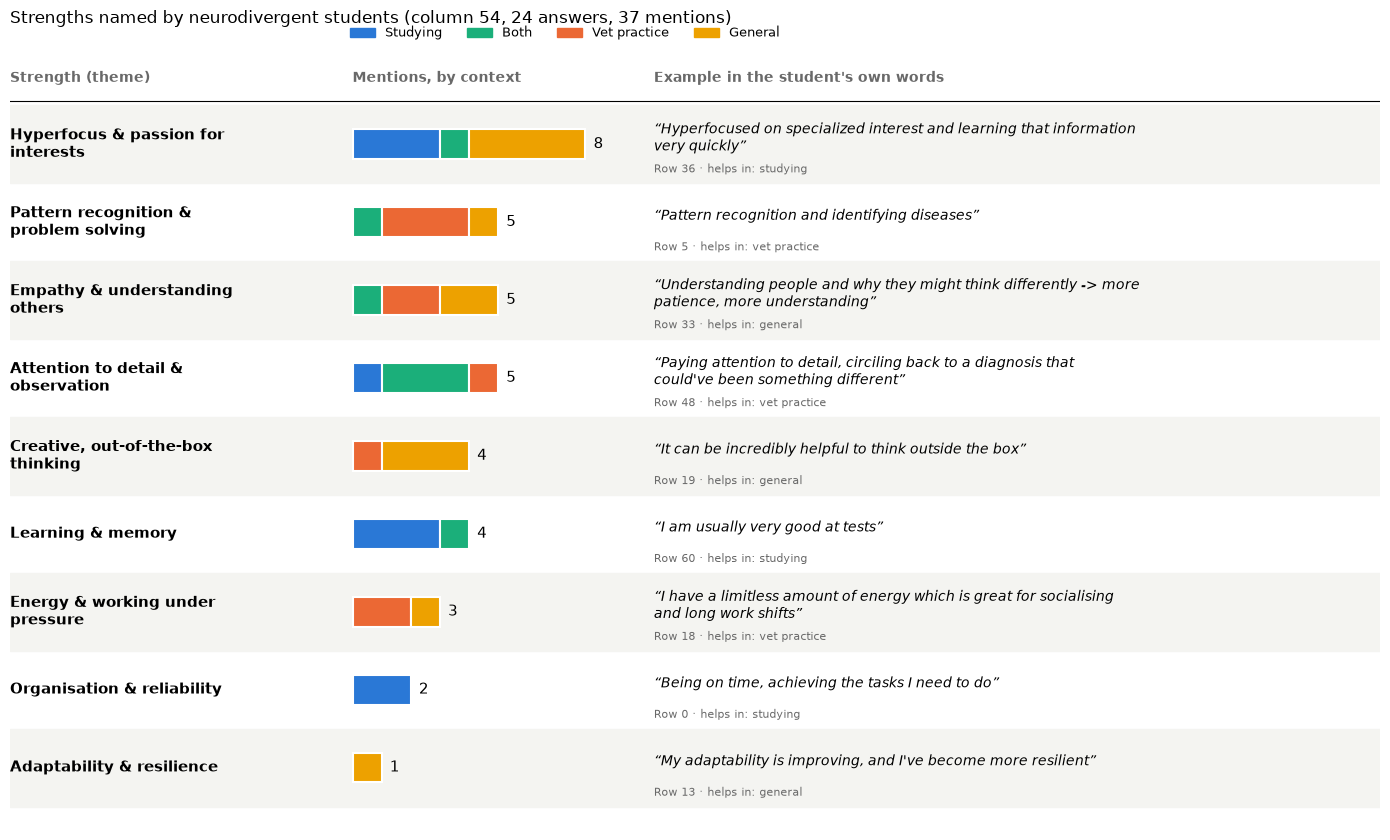

In [ ]:
# ---------------------------------------------------------------------------------------------
# Categorizing the open answers to column 54 (neurodivergent students only)
#
# Step 1 – Manual categorization (done by reading every answer)
#   Each answer was read and given two categories, written in STRENGTH_CODING below:
#     row number: (first words of the answer, context, [strength themes])
#
#   • Strength themes: what the student describes. They were not fixed in advance: after reading all
#     answers, similar strengths were grouped under one name (e.g. "hyperfocus", "special interest" and
#     "more passion for what I love" → "Hyperfocus & passion for interests").
#     One answer can name several strengths, so it can have more than one theme.
#   • Context: where the strength helps.
#       Studying     = learning, exams or university tasks
#       Vet practice = clinical work, clients, animals or diagnosis
#       Both         = the answer names a study context and a vet-practice context
#       General      = no specific context is given
#
#   To change a category, edit the row here: the chart below updates automatically.
# ---------------------------------------------------------------------------------------------
STRENGTH_CODING = {
    0:  ("Being on time",           "Studying",     ["Organisation & reliability"]),
    2:  ("I think the biggest",     "Both",         ["Pattern recognition & problem solving", "Empathy & understanding others"]),
    5:  ("Pattern recognition",     "Vet practice", ["Pattern recognition & problem solving"]),
    7:  ("Taking special interest", "Studying",     ["Hyperfocus & passion for interests"]),
    13: ("My adaptability",         "General",      ["Adaptability & resilience", "Creative, out-of-the-box thinking"]),
    18: ("I have a limitless",      "Vet practice", ["Energy & working under pressure"]),
    19: ("It can be incredibly",    "General",      ["Creative, out-of-the-box thinking", "Hyperfocus & passion for interests"]),
    24: ("I tend to hyperfocus",    "Both",         ["Hyperfocus & passion for interests"]),
    26: ("More passion",            "General",      ["Hyperfocus & passion for interests"]),
    29: ("I am very detail",        "Both",         ["Attention to detail & observation", "Learning & memory"]),
    30: ("More empathy",            "Vet practice", ["Empathy & understanding others", "Creative, out-of-the-box thinking"]),
    32: ("I can hyperfocus",        "General",      ["Hyperfocus & passion for interests", "Pattern recognition & problem solving"]),
    33: ("Understanding people",    "General",      ["Empathy & understanding others"]),
    36: ("Hyperfocused on",         "Studying",     ["Hyperfocus & passion for interests", "Learning & memory"]),
    48: ("Paying attention",        "Vet practice", ["Attention to detail & observation", "Pattern recognition & problem solving"]),
    50: ("An outside of the box",   "General",      ["Creative, out-of-the-box thinking"]),
    56: ("I think it gives",        "Vet practice", ["Empathy & understanding others"]),
    58: ("My brain works",          "General",      ["Energy & working under pressure"]),
    60: ("I must repeat",           "Studying",     ["Learning & memory", "Attention to detail & observation", "Organisation & reliability"]),
    61: ("I am very detail",        "Both",         ["Attention to detail & observation"]),
    63: ("Being able to hyper",     "Studying",     ["Hyperfocus & passion for interests", "Learning & memory"]),
    66: ("I don't really know",     "Both",         ["Attention to detail & observation"]),
    75: ("Yes in both aspects",     "Vet practice", ["Pattern recognition & problem solving", "Energy & working under pressure"]),
    78: ("I can easily feel",       "General",      ["Empathy & understanding others", "Hyperfocus & passion for interests"]),
}

# Step 2 – Safety checks, so the categories cannot end up on the wrong answer
answers_54 = nd_students["54"].dropna()  # the 24 neurodivergent students who wrote an answer
assert set(answers_54.index) == set(STRENGTH_CODING), "every ND answer to column 54 must be categorised"
for i, (start, *_ ) in STRENGTH_CODING.items():
    assert answers_54[i].startswith(start), f"row {i} does not match its categories"

# Step 3 – One line per (answer, theme): an answer with 2 themes becomes 2 lines ("mentions")
coded = pd.DataFrame([{"row": i, "context": c, "theme": t, "answer": answers_54[i]}
                      for i, (_, c, themes) in STRENGTH_CODING.items() for t in themes])
n_answers = len(answers_54)

# Step 4 – Count: how many answers name each theme, and in which context
CONTEXTS = ["Studying", "Both", "Vet practice", "General"]  # from university to the future job, then no context
CONTEXT_COLORS = {"Studying": "#2a78d6", "Both": "#1baf7a", "Vet practice": "#eb6834", "General": "#eda100"}
theme_counts = coded["theme"].value_counts()
THEMES = theme_counts.index.tolist()  # most mentioned first
theme_by_context = pd.crosstab(coded["theme"], coded["context"]).reindex(index=THEMES, columns=CONTEXTS, fill_value=0)
display(theme_by_context.assign(total=theme_counts))

# One short example quote per theme, in the students' own words (spelling kept as written).
# Each quote must appear word for word in the answer of that row, which the assert below checks.
THEME_QUOTES = {
    "Hyperfocus & passion for interests":    (36, "Hyperfocused on specialized interest and learning that information very quickly"),
    "Pattern recognition & problem solving": (5,  "Pattern recognition and identifying diseases"),
    "Empathy & understanding others":        (33, "Understanding people and why they might think differently -> more patience, more understanding"),
    "Attention to detail & observation":     (48, "Paying attention to detail, circiling back to a diagnosis that could've been something different"),
    "Creative, out-of-the-box thinking":     (19, "It can be incredibly helpful to think outside the box"),
    "Learning & memory":                     (60, "I am usually very good at tests"),
    "Energy & working under pressure":       (18, "I have a limitless amount of energy which is great for socialising and long work shifts"),
    "Organisation & reliability":            (0,  "Being on time, achieving the tasks I need to do"),
    "Adaptability & resilience":             (13, "My adaptability is improving, and I've become more resilient"),
}
assert set(THEME_QUOTES) == set(THEMES), "every theme needs one quote"
for theme, (row, quote) in THEME_QUOTES.items():
    assert quote in answers_54[row], f"quote for '{theme}' is not in row {row}"
    assert theme in STRENGTH_CODING[row][2], f"row {row} is not coded with '{theme}'"

fig, ax = plt.subplots(figsize=(14, 8.5))
ax.set_xlim(0, 1)
ax.set_ylim(len(THEMES) - 0.2, -1.2)
ax.axis("off")
X_THEME, X_BAR, X_QUOTE = 0.0, 0.25, 0.47
BAR_W = 0.17 / theme_counts.max()  # width of one mention

for x, header in [(X_THEME, "Strength (theme)"), (X_BAR, "Mentions, by context"), (X_QUOTE, "Example in the student's own words")]:
    ax.text(x, -0.85, header, fontsize=10, fontweight="bold", color="dimgrey", va="center")
ax.axhline(-0.55, color="black", linewidth=0.8)

for y, theme in enumerate(THEMES):
    if y % 2 == 0:  # light band on every other row to guide the eye
        ax.axhspan(y - 0.5, y + 0.5, color="#f4f4f1", zorder=0)
    ax.text(X_THEME, y, textwrap.fill(theme, 26), fontsize=10.5, fontweight="bold", va="center")

    # Mini stacked bar: number of answers per context
    left = X_BAR
    for context in CONTEXTS:
        k = theme_by_context.loc[theme, context]
        if k:
            ax.barh(y, k * BAR_W, left=left, height=0.38, color=CONTEXT_COLORS[context],
                    edgecolor="white", linewidth=1.5)
            left += k * BAR_W
    ax.text(left + 0.006, y, str(theme_counts[theme]), fontsize=10.5, va="center")

    row, quote = THEME_QUOTES[theme]
    context = STRENGTH_CODING[row][1]
    ax.text(X_QUOTE, y - 0.08, textwrap.fill(f"“{quote}”", 70), fontsize=10, style="italic", va="center")
    ax.text(X_QUOTE, y + 0.32, f"Row {row} · helps in: {context.lower()}",
            fontsize=8, color="dimgrey", va="center")

context_handles = [plt.Rectangle((0, 0), 1, 1, color=CONTEXT_COLORS[c]) for c in CONTEXTS]
ax.legend(context_handles, CONTEXTS, ncol=4, loc="lower left",
          bbox_to_anchor=(X_BAR - 0.01, 1.0), frameon=False, fontsize=9)
ax.set_title(f"Strengths named by neurodivergent students (column 54, {n_answers} answers, "
             f"{len(coded)} mentions)", loc="left", fontsize=12, pad=20)
plt.tight_layout()
plt.show()

## Perceived social support

### Support from partner, family and friends

**Columns used**
- Columns **86–97** are the 12 items of the **MSPSS** (*Multidimensional Scale of Perceived Social Support*), each answered from 1 (*very strongly disagree*) to 7 (*very strongly agree*). They form three groups of 4 items:
  - **Partner (86–89)**: *"There is a special person who…"*
  - **Family (90–93)**: *"My family…"*
  - **Friends (94–97)**: *"My friends…"*
- **No partner = N/A.** 26 of the 79 students answered 1 on all four partner items. These are almost certainly students without a partner, not students whose partner gives them no support, so their partner answers are treated as N/A.

**What the graph shows (diverging stacked bars)**
- One bar per item, grouped by source of support. The item text is shortened; the full wording is in the codebook.
- Disagree answers (1–3, red) go **left** of the centre line and agree answers (5–7, blue) go **right**. Neutral answers (4, grey) are split in half across the centre. The further a bar reaches right, the more support students feel.
- Partner bars use only the 53 students with a partner. The hatched panel on the right shows the share of all 79 students with no partner (N/A).
- Numbers inside the bars are the % of students who answered the item.

**Conclusions**
- **Partner**: students who have a partner feel strongly supported. 74–83% agree with each item and at most 11% disagree.
- **Friends**: support is high and consistent. About 72–73% agree with every item, and only 9–13% disagree.
- **Family is the weakest and most split source, especially for emotional support.** Only about half of the students get the emotional help they need from their family (91: 49% agree) or can talk to them about their problems (92: 51%), and 37% disagree with each. Practical help is rated better: the family tries to help (90: 60% agree) and helps with decisions (93: 63%).

**Limits**
- The "no partner" rule is an assumption: a student with a partner who really disagreed with all four items would also be counted as N/A. The survey did not ask directly whether students have a partner.

No partner (all four partner items = 1): 26 of 79 students


,source,item,n,N/A,% disagree (1–3),% neutral (4),% agree (5–7),average
0,Partner,Is around when I am in need (86),53,26,11.3,11.3,77.4,5.6
1,Partner,Shares my joys and sorrows (87),53,26,7.5,18.9,73.6,5.7
2,Partner,Is a real source of comfort (88),53,26,7.5,15.1,77.4,5.8
3,Partner,Cares about my feelings (89),53,26,3.8,13.2,83.0,6.0
4,Family,Really tries to help me (90),79,0,21.5,19.0,59.5,5.1
5,Family,Gives the emotional help I need (91),79,0,36.7,13.9,49.4,4.4
6,Family,I can talk about my problems with them (92),79,0,36.7,12.7,50.6,4.3
7,Family,Helps me make decisions (93),79,0,21.5,15.2,63.3,5.0
8,Friends,Really try to help me (94),79,0,11.4,16.5,72.2,5.4
9,Friends,I can count on them when things go wrong (95),79,0,8.9,19.0,72.2,5.4


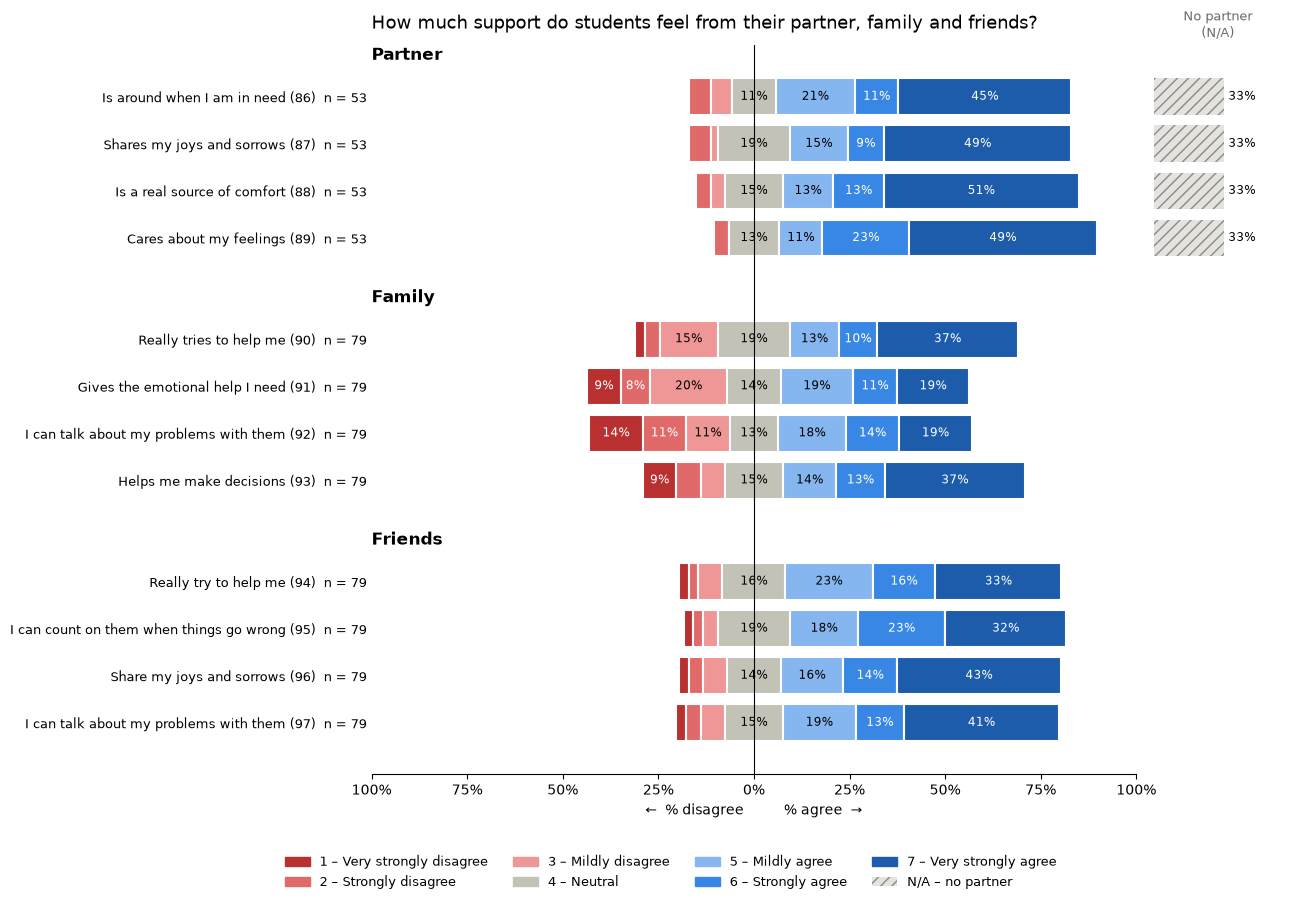

In [ ]:
# MSPSS (Multidimensional Scale of Perceived Social Support): 12 items, 1-7, in three sources of 4 items
MSPSS = {
    "Partner": [("86", "Is around when I am in need"),
                ("87", "Shares my joys and sorrows"),
                ("88", "Is a real source of comfort"),
                ("89", "Cares about my feelings")],
    "Family":  [("90", "Really tries to help me"),
                ("91", "Gives the emotional help I need"),
                ("92", "I can talk about my problems with them"),
                ("93", "Helps me make decisions")],
    "Friends": [("94", "Really try to help me"),
                ("95", "I can count on them when things go wrong"),
                ("96", "Share my joys and sorrows"),
                ("97", "I can talk about my problems with them")],
}
PARTNER_COLS = [col for col, _ in MSPSS["Partner"]]
MSPSS_LEVELS = ["1 – Very strongly disagree", "2 – Strongly disagree", "3 – Mildly disagree", "4 – Neutral",
                "5 – Mildly agree", "6 – Strongly agree", "7 – Very strongly agree"]
# Same red → grey → blue scale as the earlier Likert charts, with one extra step on each side for the 7-point scale
MSPSS_COLORS = ["#b8302f", "#e06a69", "#ee9796", "#c3c2b7", "#86b6ef", "#3987e5", "#1c5cab"]
NA_COLOR = "#e4e3df"

# Students who answered 1 on all four partner items almost certainly have no partner: they are N/A, not "no support"
df["no_partner"] = (df[PARTNER_COLS] == 1).all(axis=1)
mspss = df[[col for items in MSPSS.values() for col, _ in items]].astype(float)
mspss.loc[df["no_partner"], PARTNER_COLS] = np.nan
print(f"No partner (all four partner items = 1): {df['no_partner'].sum()} of {len(df)} students")

rows = []
for source, items in MSPSS.items():
    for col, text in items:
        answers = mspss[col].dropna()
        rows.append({"source": source, "item": f"{text} ({col})", "n": len(answers),
                     "N/A": len(df) - len(answers),
                     "% disagree (1–3)": (answers <= 3).mean() * 100,
                     "% neutral (4)": (answers == 4).mean() * 100,
                     "% agree (5–7)": (answers >= 5).mean() * 100,
                     "average": answers.mean()})
display(pd.DataFrame(rows).round(1))

fig, (ax, ax_na) = plt.subplots(1, 2, figsize=(13, 9), sharey=True, gridspec_kw={"width_ratios": [6, 1], "wspace": 0.04})
yticks, ylabels, y = [], [], 0
for source, items in MSPSS.items():
    ax.text(-1.0, y - 0.15, source, fontsize=12, fontweight="bold", va="bottom")
    y += 0.55
    for col, text in items:
        answers = mspss[col].dropna()
        shares = answers.value_counts(normalize=True).reindex(range(1, 8), fill_value=0).values
        # Centre the bar on the middle of the neutral answer: 1–3 to the left, 5–7 to the right
        left = -(shares[:3].sum() + shares[3] / 2)
        for share, color in zip(shares, MSPSS_COLORS):
            ax.barh(y, share, left=left, height=0.78, color=color, edgecolor="white", linewidth=1.5)
            if share >= 0.07:  # label only segments wide enough to hold the text
                ax.text(left + share / 2, y, f"{share:.0%}", ha="center", va="center", fontsize=8.5,
                        color="white" if color in ("#b8302f", "#e06a69", "#3987e5", "#1c5cab") else "black")
            left += share
        # Right panel: students the item does not apply to (no partner), as % of the whole sample
        na_share = 1 - len(answers) / len(df)
        if na_share > 0:
            ax_na.barh(y, na_share, height=0.78, color=NA_COLOR, edgecolor="#8a8984", hatch="///", linewidth=0)
            ax_na.text(na_share + 0.02, y, f"{na_share:.0%}", va="center", fontsize=8.5)
        yticks.append(y)
        ylabels.append(f"{text} ({col})  n = {len(answers)}")
        y += 1
    y += 0.6

ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(yticks, ylabels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-1, 1)
ax.set_xticks(np.arange(-1, 1.01, 0.25))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{abs(x):.0%}"))
ax.set_xlabel("←  % disagree          % agree  →")
ax.set_title("How much support do students feel from their partner, family and friends?", loc="left", fontsize=13, pad=12)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

ax_na.set_xlim(0, 0.6)
ax_na.set_xticks([])
ax_na.set_title("No partner\n(N/A)", fontsize=9, color="dimgrey")
ax_na.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax_na.tick_params(axis="y", length=0)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in MSPSS_COLORS]
handles.append(plt.Rectangle((0, 0), 1, 1, facecolor=NA_COLOR, edgecolor="#8a8984", hatch="///", linewidth=0))
fig.legend(handles, MSPSS_LEVELS + ["N/A – no partner"], ncol=4, loc="lower center",
           bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=9)
fig.subplots_adjust(left=0.27, right=0.97, top=0.93, bottom=0.12)
plt.show()

### Support by source: neurodivergent vs not neurodivergent students

**Columns used**
- Each student gets **one score per source**: the average of its 4 MSPSS items (the official scoring), from 1 to 7. Partner scores leave out the 26 students with no partner.
- Neurodivergent vs not neurodivergent (column 9, as in the first chart).

**What the graph shows (box plots with every student as a dot)**
- For each source there are two boxes: **neurodivergent** (blue) and **not neurodivergent** (orange). The thick line is the median, the box holds the middle half of the students, and each dot is one student.
- The background bands are the standard MSPSS levels: **low** (1–2.9), **moderate** (3–5) and **high** (5.1–7).
- The p-value above each pair compares the two groups.

**Method**
- **Mann-Whitney U test** (ND vs not ND, for each source): checks whether one group tends to feel more support. p < 0.05 = significant.
- **Friedman test** (partner vs family vs friends): the same students rated all three sources, so a *paired* test is used. It only includes the 53 students who have a partner.
- **Wilcoxon signed-rank tests** (paired, two sources at a time) to see which sources differ: family vs friends uses all 79 students, the comparisons with partner use the 53 students with a partner.

**Reading the numbers**
- **Friedman p < 0.001**: if students had no general preference between partner, family and friends, their rankings of the three sources would be this unbalanced almost never. So at least one source differs; the Wilcoxon tests show which.
- **Family vs friends (4.7 vs 5.4) and family vs partner (4.8 vs 5.8): Wilcoxon p < 0.001.** Most students rate family below the other two, far more often than chance would allow.
- **Partner vs friends (5.8 vs 5.4): p = 0.28.** A gap like this would appear by chance more than 1 time in 4, so there is no evidence that one is rated higher.
- **ND vs not ND: Mann-Whitney p = 0.46 to 0.81.** The averages are slightly lower for ND students, but gaps of this size are very common by chance.

**Conclusions**
- **Students feel the least support from their family** (Friedman p < 0.001). Family is rated lower than friends (average 4.7 vs 5.4, p < 0.001) and lower than partner (4.8 vs 5.8, p < 0.001).
- **Partner and friends give similar support** (5.8 vs 5.4, p = 0.28).
- **Neurodivergent and non-neurodivergent students feel similar levels of support.** Neurodivergent students' averages are slightly lower for all three sources, but no difference is significant (p = 0.46–0.81).
- Neurodivergent students fall in the *low* support band a little more often (friends 10% vs 3%, partner 7% vs 0%, family 17% vs 14%), but the groups are small and this could be chance.

,n ND,n not ND,median ND,median not ND,average ND,average not ND,p-value ND vs not ND
source,,,,,,,
Partner,27,26,6.50,6.125,5.611,5.933,0.705
Family,42,37,4.50,5.000,4.560,4.858,0.457
Friends,42,37,5.25,6.000,5.321,5.561,0.808


Friedman test, partner vs family vs friends (n = 53): p = 0.000
Wilcoxon family vs friends (n = 79): average 4.70 vs 5.43, p = 0.000
Wilcoxon partner vs family (n = 53): average 5.77 vs 4.76, p = 0.000
Wilcoxon partner vs friends (n = 53): average 5.77 vs 5.45, p = 0.284


Low  Moderate  High
        nd_group                                
Partner Neurodivergent       7.0      33.0  59.0
        Not neurodivergent   0.0      31.0  69.0
Family  Neurodivergent      17.0      43.0  40.0
        Not neurodivergent  14.0      38.0  49.0
Friends Neurodivergent      10.0      38.0  52.0
        Not neurodivergent   3.0      32.0  65.0

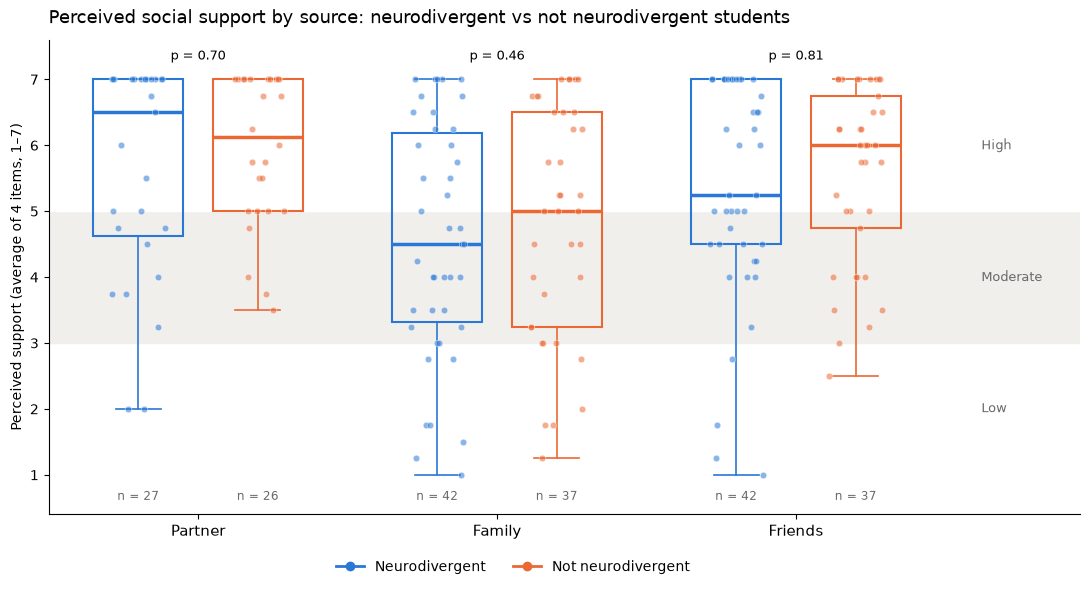

In [ ]:
# Subscale score = average of the 4 items (official MSPSS scoring). Partner is left empty for students with no partner
SOURCES = list(MSPSS)
scores = pd.DataFrame({source: mspss[[col for col, _ in items]].mean(axis=1) for source, items in MSPSS.items()})
scores["nd_group"] = df["nd_group"]
GROUPS = [("Neurodivergent", ND_COLOR), ("Not neurodivergent", NON_ND_COLOR)]

rows = []
for source in SOURCES:
    nd_s = scores.loc[scores["nd_group"] == "Neurodivergent", source].dropna()
    non_s = scores.loc[scores["nd_group"] == "Not neurodivergent", source].dropna()
    rows.append({"source": source, "n ND": len(nd_s), "n not ND": len(non_s),
                 "median ND": nd_s.median(), "median not ND": non_s.median(),
                 "average ND": nd_s.mean(), "average not ND": non_s.mean(),
                 # Mann-Whitney U test: do ND students tend to feel more or less support than the others?
                 "p-value ND vs not ND": stats.mannwhitneyu(nd_s, non_s).pvalue})
mw = pd.DataFrame(rows).set_index("source")
display(mw.round(3))

# Which source do students feel most support from? Friedman test on students who answered all three (have a partner)
complete = scores[SOURCES].dropna()
print(f"Friedman test, partner vs family vs friends (n = {len(complete)}): p = {stats.friedmanchisquare(*[complete[s] for s in SOURCES]).pvalue:.3f}")
for a, b in [("Family", "Friends"), ("Partner", "Family"), ("Partner", "Friends")]:
    pair = scores[[a, b]].dropna()
    print(f"Wilcoxon {a.lower()} vs {b.lower()} (n = {len(pair)}): average {pair[a].mean():.2f} vs {pair[b].mean():.2f}, "
          f"p = {stats.wilcoxon(pair[a], pair[b]).pvalue:.3f}")

# Standard MSPSS levels: low 1–2.9, moderate 3–5, high 5.1–7
levels = scores[SOURCES].apply(lambda s: pd.cut(s, [0, 2.99, 5.0, 7], labels=["Low", "Moderate", "High"]))
level_share = pd.concat({s: levels[s].groupby(scores["nd_group"]).value_counts(normalize=True).unstack() for s in SOURCES})
display((level_share * 100).round(0))

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(11, 6))
# Background bands for the low / moderate / high levels
for lo, hi, label in [(1, 3, "Low"), (3, 5, "Moderate"), (5, 7, "High")]:
    ax.axhspan(lo, hi, color="#f0efec" if label == "Moderate" else "white", zorder=0)
    ax.text(2.62, (lo + hi) / 2, label, ha="left", va="center", fontsize=9, color="dimgrey")
offsets = [-0.2, 0.2]
for i, source in enumerate(SOURCES):
    for (group, color), dx in zip(GROUPS, offsets):
        s = scores.loc[scores["nd_group"] == group, source].dropna()
        ax.boxplot(s, positions=[i + dx], widths=0.3, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor="none", edgecolor=color, linewidth=1.5),
                   medianprops=dict(color=color, linewidth=2.5),
                   whiskerprops=dict(color=color, linewidth=1.2), capprops=dict(color=color, linewidth=1.2))
        ax.scatter(i + dx + rng.uniform(-0.09, 0.09, len(s)), s, s=22, color=color, alpha=0.55,
                   edgecolor="white", linewidth=0.5, zorder=3)
        ax.text(i + dx, 0.62, f"n = {len(s)}", ha="center", fontsize=8.5, color="dimgrey")
    p = mw.loc[source, "p-value ND vs not ND"]
    ax.text(i, 7.3, f"p = {p:.2f}" + (" *" if p < 0.05 else ""), ha="center", fontsize=9.5)

ax.set_xticks(range(len(SOURCES)), [f"{s}" for s in SOURCES], fontsize=11)
ax.set_xlim(-0.5, 2.95)
ax.set_ylim(0.4, 7.6)
ax.set_yticks(range(1, 8))
ax.set_ylabel("Perceived support (average of 4 items, 1–7)")
ax.set_title("Perceived social support by source: neurodivergent vs not neurodivergent students", loc="left", fontsize=13, pad=12)
ax.legend([plt.Line2D([], [], color=c, marker="o", linewidth=2) for _, c in GROUPS], [g for g, _ in GROUPS],
          loc="upper center", bbox_to_anchor=(0.45, -0.07), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Summary of statistical results

Every test in the notebook in one table. **Size** is the effect (averages, % or ρ); **p** is how likely a result this extreme would be by chance alone. The last column says how solid the result is, following *Statistical methods* (p < 0.001 or repeated across related questions = solid; p close to 0.05 = hint; p > 0.05 = not shown).

| Topic | Comparison | Test | Size | p | Reading |
|---|---|---|---|---|---|
| Overwhelm score | Expectations (26) vs workload (27) | Spearman | ρ = 0.73 | < 0.001 | **Solid**: strong link, the two questions can be combined |
| Overwhelm groups | Feeling anxious or overwhelmed, high vs low | Mann-Whitney | 4.2 vs 3.5 | 0.003 | **Significant** |
| | Stress, high vs low | Mann-Whitney | 4.3 vs 3.7 | 0.011 | **Significant** |
| | Mental state since uni, high vs low | Mann-Whitney | 2.0 vs 2.8 | 0.014 | **Significant**: worse for highly overwhelmed |
| | Feeling depressed, high vs low | Mann-Whitney | 3.3 vs 2.6 | 0.084 | Not significant (low group has only 11 students) |
| Overwhelm links | Depression, anxious/overwhelmed, depressed, stress | Spearman | ρ = 0.38 to 0.45 | < 0.001 | **Solid**: moderate links |
| | Mental state since uni | Spearman | ρ = −0.43 | < 0.001 | **Solid**: more overwhelm, more worsened |
| | Anxiety (GAD-7) | Spearman | ρ = 0.26 | 0.023 | **Significant**, weak link |
| Year of study | Depression, graduates vs current students | Mann-Whitney | 10.3 vs 15.4 | 0.010 | **Significant**, but only 10 graduates |
| | Anxiety, graduates vs current students | Mann-Whitney | 8.9 vs 12.7 | 0.088 | Not significant, same direction |
| | Middle or final year vs other students | Mann-Whitney | — | 0.23 to 0.94 | No difference shown |
| Lifestyle | Eat regular meals vs year | Spearman | ρ = 0.26 | 0.034 | Hint: weak, 1 of 8 trends tested |
| | Other lifestyle questions and stress vs year | Spearman | \|ρ\| ≤ 0.19 | ≥ 0.13 | No trend shown |
| Defining ND | *A unique way of thinking*, ND vs not ND | Fisher | 17% vs 36% | 0.069 | Not significant, hint |
| | Other answers, ND vs not ND | Fisher | — | 0.21 to 0.62 | No difference shown |
| Environment | Family vs cultural environment | Wilcoxon | 3.03 vs 2.73 | 0.042 | **Significant**, close to the line |
| | Professors (24) vs teaching style (23) | Spearman | ρ = 0.60 | < 0.001 | **Solid**: strong link |
| | ND vs not ND, all five environments | Mann-Whitney | — | 0.10 to 0.82 | No difference shown |
| Fear of disclosure | Diagnosed vs self-identified | Mann-Whitney | 3.24 vs 3.33 | 0.92 | No difference shown |
| | Comfort at university, classmates | Spearman | ρ = 0.28, 0.26 | 0.078, 0.10 | Not significant, could be real (n = 40) |
| Challenges | Ranking: all ND vs those who rated all 12 | Spearman | ρ = 0.85 | < 0.001 | **Solid**: ranking not affected by answering style |
| | By condition (48 tests) | Fisher | — | 4 tests < 0.05 | Hints only: about 2.4 expected by chance |
| Strengths | As a student (52) vs as a future vet (53) | McNemar | 44% vs 63% yes | 0.008 | **Significant**: 8 changed No → Yes, none Yes → No |
| Social support | Partner vs family vs friends | Friedman | — | < 0.001 | **Solid**: sources differ |
| | Family vs friends / family vs partner | Wilcoxon | 4.7 vs 5.4 / 4.8 vs 5.8 | < 0.001 | **Solid**: family is the lowest |
| | Partner vs friends | Wilcoxon | 5.8 vs 5.4 | 0.28 | No difference shown |
| | ND vs not ND, each source | Mann-Whitney | — | 0.46 to 0.81 | No difference shown |

**Overall**
- **The most solid findings** are the very high levels of distress, the strong links between academic overwhelm and distress, family being the weakest source of support, and the university's teaching side being seen as the least accessible.
- **Neurodivergent and non-neurodivergent students rarely differ significantly.** With about 40 students per group, only large differences can be detected, so this means "no large difference", not "no difference".
- **Results with p between 0.01 and 0.05**, and the single stars in the challenges-by-condition heatmap, should be presented as findings to confirm in a larger sample.